# Cardiac MRI (ACDC): segmentation, error propagation and diagnosis

**AUB Machine Learning course project, Fall 2026.** Mohammad Alaa Al Din Al Hamwi, Abdulrahman Kaddoura, Hamza Rachidi.

- Code repository: <https://github.com/Hamza-69/detection-ml-project>
- Trained models (download): <https://github.com/Hamza-69/detection-ml-project/releases/tag/v1.0-final>
- Live demo: <https://acdc-cardiac-aub.fly.dev/>

**Dataset change.** The proposal and milestone 2 used VinDr-CXR. Its official test labels (PhysioNet, credentialed
access) could not be obtained, so, as allowed by the instructor, the final project uses the alternative dataset ACDC
(Automated Cardiac Diagnosis Challenge, MICCAI 2017), which has an official, public, independent test set.

### How this notebook is organised
The pipeline is a set of small Python modules in `acdc/` (one per step). Each section of this notebook

1. explains the step and the reasons for the modelling choices,
2. **shows the complete source code of the module(s)** for that step (so the notebook contains all the code),
3. has a cell that **runs** the step (switched off by default: the full pipeline needs about 30 GPU-hours on an
   NVIDIA L40S, see the `RUN` flags below), and
4. loads and displays the step's **results** from `results/` (tables, figures). Every number shown is read from a file
   produced by the code; nothing is typed by hand.

To reproduce everything: download ACDC (see the README), set `ACDC_ROOT` / `ACDC_WORK`, set the `RUN` flags to `True`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
from IPython.display import Code, Image, Markdown, display

REPO = Path.cwd()                       # run the notebook from the repository root
assert (REPO / "acdc").is_dir(), "start Jupyter in the repository root"
sys.path.insert(0, str(REPO))
R = REPO / "results"
pd.set_option("display.precision", 3, "display.max_columns", 30, "display.width", 200)

# Switch steps on to re-run them (GPU steps need a CUDA GPU; times measured on 1x L40S, 8 vCPU)
RUN = dict(
    prepare=False,          # ~5 min CPU   : read 150 patients, resample, cache, folds
    seg_baseline=False,     # ~2 h CPU     : classical LightGBM pixel classifier (5 folds + predictions)
    tune_baseline=False,    # ~1 h CPU     : LightGBM hyper-parameter grid
    train_unet=False,       # ~6.5 h GPU   : 2D U-Net, 5 folds x 250 epochs (ablations: another ~20 h)
    predict_unet=False,     # ~3 min GPU   : out-of-fold + test predictions
    train_cnn=False,        # ~15 min GPU  : end-to-end CNN, 5 seeds x 5 folds
    classify=False,         # ~10 min CPU  : diagnosis classifiers (nested CV)
    evaluate=False,         # ~15 min      : evaluation, robustness, Grad-CAM, complexity, summary
    split_sensitivity=False,  # ~5 min CPU : re-drawn folds and random train/test splits
)

def run(cmd):
    """Run one pipeline command from the repo root and stream its output."""
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=REPO)

def show_code(*paths):
    """Display the full source of pipeline files (this is how the notebook contains all the code)."""
    for p in paths:
        display(Markdown(f"**`{p}`**"))
        display(Code(filename=str(REPO / p), language="bash" if p.endswith(".sh") else "python"))

def fig(path, width=900):
    display(Image(filename=str(R / path), width=width))

def jload(path):
    return json.loads((R / path).read_text())

## 1. Problem, research question and hypotheses

Cine cardiac MRI is the reference exam for cardiac function. Cardiologists contour the left-ventricle (LV) cavity,
the LV myocardium (MYO) and the right-ventricle (RV) cavity at end-diastole (ED) and end-systole (ES), compute
clinical indices (volumes, ejection fraction, myocardial mass) and use them for the diagnosis. Manual contouring is
slow, so automation matters, but with small datasets it is unclear how a diagnosis system should be built.

**Question.** With only 100 training patients, should a diagnosis system be an interpretable *two-stage* pipeline
(segmentation, then clinical indices, then a classical classifier) or an *end-to-end* CNN? How do segmentation errors
propagate into the indices and the diagnosis, and can the system tell when it is wrong?

- **H1 (segmentation ladder).** A 2D U-Net clearly beats a tuned classical per-pixel classifier (hand-crafted
  multiscale features + LightGBM) on Dice and HD95 for all structures.
- **H2 (error propagation).** Indices from U-Net masks agree closely with the expert ones (Pearson r >= 0.95), and
  diagnosis from predicted masks is within 5 accuracy points of diagnosis from expert masks.
- **H3 (two-stage vs end-to-end).** With 100 patients the two-stage pipeline is at least as accurate as an end-to-end
  CNN and better calibrated.
- **H4 (reliability).** (a) uncertainty flags bad segmentations, (b) augmentation makes the U-Net robust to image
  degradations, (c) the end-to-end CNN's Grad-CAM concentrates on the heart.

**Model ladder.** Segmentation: LightGBM pixel classifier (level 1) vs U-Net (level 2). Diagnosis: logistic
regression / random forest on image features (level 1, no segmentation) vs end-to-end CNN (level 2), and the
two-stage pipelines in between.

## 2. Dataset and preprocessing

ACDC: 150 patients, 5 balanced groups (NOR normal, MINF previous infarction, DCM dilated cardiomyopathy, HCM
hypertrophic cardiomyopathy, RV abnormal right ventricle). Official split: 100 training patients (20 per group),
50 test patients (10 per group). Expert masks of RV, MYO, LV at ED and ES; height and weight per patient.

Preprocessing (`acdc/prepare.py`, helpers in `acdc/common.py`):
- read the ED and ES volumes and masks (NIfTI); slices are kept 2D because slice thickness (5-10 mm) is much larger
  than the in-plane spacing;
- resample every slice in-plane to 1.25 mm (bilinear for images, nearest for masks), so one pixel has the same size
  for all patients; z-score intensities per volume (robust to scanner gain);
- clinical indices from the expert masks (volumes, EF, mass, body-surface-area indexed values);
- **5 folds** on the 100 training patients, stratified by group, seed 42, written once to `results/acdc_meta.csv` and
  never changed. Every model is trained on 4 folds and predicts the 5th (out-of-fold), so all 100 training patients
  get honest predictions. The 50 test patients are used once, at the end.

Data audit: no missing values; the five groups are perfectly balanced; slice count, spacing and thickness differ
between patients (summary below), which is why we resample.

In [2]:
show_code('acdc/common.py', 'acdc/prepare.py')

**`acdc/common.py`**

"""Shared helpers for the ACDC pipeline: paths, loading, resampling, metrics and clinical indices.

ACDC label convention (ground-truth files *_gt.nii.gz):
    0 = background, 1 = right-ventricle (RV) cavity, 2 = left-ventricle myocardium (MYO), 3 = left-ventricle (LV) cavity.
Arrays from nibabel are (X, Y, Z); we work with (Z, X, Y) stacks of 2D short-axis slices.
"""
from __future__ import annotations

import os
from pathlib import Path

import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage

# ----------------------------------------------------------------------------------------------- paths
DATA_ROOT = Path(os.environ.get("ACDC_ROOT", "/home/ubuntu/data/acdc/raw/ACDC/database"))
WORK = Path(os.environ.get("ACDC_WORK", "/home/ubuntu/data/acdc/work"))  # caches, checkpoints, predictions
REPO = Path(__file__).resolve().parents[1]
RESULTS = REPO / "results"  # small tables / figures / json that go into git

CLASSES = {1: "RV", 2: "MYO", 3: "LV"}
GROUPS = ["NOR", "MINF", "DCM", "HCM", "RV"]  # NOR normal, MINF previous infarction, DCM dilated, HCM hypertrophic, RV abnormal RV
TARGET_SPACING = 1.25  # mm, in-plane spacing all slices are resampled to for the networks
MYO_DENSITY = 1.05  # g/mL, to turn myocardial volume into mass


# ----------------------------------------------------------------------------------------------- loading
def patient_dir(pid: str) -> Path:
    n = int(pid[-3:])
    return DATA_ROOT / ("training" if n <= 100 else "testing") / pid


def read_info(pid: str) -> dict:
    """Info.cfg -> dict(ED, ES, Group, Height, Weight, NbFrame)."""
    info = {}
    for line in (patient_dir(pid) / "Info.cfg").read_text().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            info[k.strip()] = v.strip()
    return {"ED": int(info["ED"]), "ES": int(info["ES"]), "group": info["Group"], "height": float(info["Height"]),
            "weight": float(info["Weight"]), "n_frames": int(info["NbFrame"])}


def load_phase(pid: str, phase: str, info: dict | None = None):
    """Return image (Z,X,Y) float32, ground truth (Z,X,Y) uint8, spacing (sx, sy, sz) in mm for phase 'ED' or 'ES'."""
    info = info or read_info(pid)
    stem = patient_dir(pid) / f"{pid}_frame{info[phase]:02d}"
    im = nib.load(f"{stem}.nii.gz")
    img = np.asarray(im.dataobj, dtype=np.float32).transpose(2, 0, 1)
    gt = np.asarray(nib.load(f"{stem}_gt.nii.gz").dataobj).astype(np.uint8).transpose(2, 0, 1)
    spacing = tuple(float(s) for s in im.header.get_zooms()[:3])
    return img, gt, spacing


# ----------------------------------------------------------------------------------------------- preprocessing
def normalize(img: np.ndarray) -> np.ndarray:
    """Clip to the volume's 0.5-99.5 percentiles, then z-score (MRI intensities have no absolute scale)."""
    lo, hi = np.percentile(img, [0.5, 99.5])
    img = np.clip(img, lo, hi)
    return ((img - img.mean()) / (img.std() + 1e-8)).astype(np.float32)


def resampled_shape(shape_xy, spacing_xy, target=TARGET_SPACING):
    return tuple(int(round(n * s / target)) for n, s in zip(shape_xy, spacing_xy))


def resample_image(img: np.ndarray, spacing_xy, target=TARGET_SPACING) -> np.ndarray:
    """(Z,X,Y) image -> in-plane spacing `target` (bilinear, slice by slice; z untouched)."""
    out = resampled_shape(img.shape[1:], spacing_xy, target)
    t = torch.from_numpy(img)[:, None]
    return F.interpolate(t, size=out, mode="bilinear", align_corners=False)[:, 0].numpy()


def resample_labels(lab: np.ndarray, size_xy, n_classes=4) -> np.ndarray:
    """Resample a label map by linearly interpolating its one-hot encoding and taking argmax (smoother than nearest)."""
    t = F.one_hot(torch.from_numpy(lab.astype(np.int64)), n_classes).permute(0, 3, 1, 2).float()
    return F.interpolate(t, size=tuple(size_xy), mode="bilinear", align_corners=False).argmax(1).numpy().astype(np.uint8)


def probs_to_original(prob: torch.Tensor,

**`acdc/prepare.py`**

"""Step 1 - read all 150 ACDC patients once and build everything later steps need.

Writes
  WORK/cache/<pid>.npz        ED and ES images resampled to 1.25 mm in-plane and z-scored (float16), their label maps
                              resampled the same way (uint8), plus the original spacing / shape (used to map back).
  results/acdc_meta.csv       one row per patient: split (train/test), CV fold, group, height, weight, frames, spacing,
                              ground-truth clinical indices (from the original-resolution masks).
  results/data_summary.json   counts used in the report.
  results/fig_examples.png    one mid-ventricular ED slice with its ground truth per diagnostic group.

Splits: the official ACDC split is kept - patients 001-100 = training (5-fold CV, stratified by group, seed 42),
patients 101-150 = held-out test set (10 per group), never used for training, tuning or model selection.
"""
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

from acdc.common import (GROUPS, RESULTS, WORK, body_surface_area, clinical_indices, load_phase, normalize,
                         read_info, resample_image, resample_labels)


def main():
    (WORK / "cache").mkdir(parents=True, exist_ok=True)
    RESULTS.mkdir(exist_ok=True)
    rows, examples = [], {}
    for n in range(1, 151):
        pid = f"patient{n:03d}"
        info = read_info(pid)
        arrays = {}
        for phase in ("ED", "ES"):
            img, gt, sp = load_phase(pid, phase, info)
            img_r = resample_image(normalize(img), sp[:2])
            arrays[f"img_{phase}"] = img_r.astype(np.float16)
            arrays[f"lab_{phase}"] = resample_labels(gt, img_r.shape[1:])
            if phase == "ED":
                gt_ed = gt
            else:
                gt_es = gt
        np.savez_compressed(WORK / "cache" / f"{pid}.npz", spacing=np.array(sp), orig_shape=np.array(img.shape), **arrays)
        row = {"pid": pid, "split": "train" if n <= 100 else "test", **info,
               "sx": sp[0], "sy": sp[1], "sz": sp[2], "n_slices": img.shape[0], "nx": img.shape[1], "ny": img.shape[2],
               "bsa": body_surface_area(info["height"], info["weight"])}
        row.update({f"gt_{k}": v for k, v in clinical_indices(gt_ed, gt_es, sp).items()})
        rows.append(row)
        if n <= 100 and info["group"] not in examples:  # first training patient of each group for the figure
            z = int(np.argmax((arrays["lab_ED"] == 3).sum((1, 2))))  # slice with the largest LV cavity
            examples[info["group"]] = (arrays["img_ED"][z].astype(np.float32), arrays["lab_ED"][z], pid)
        print(pid, info["group"], img.shape, sp, flush=True)

    meta = pd.DataFrame(rows)
    # 5-fold CV on the 100 training patients, stratified by diagnostic group (20 per group -> 4 per group per fold).
    meta["fold"] = -1
    tr = meta.index[meta.split == "train"]
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    for f, (_, va) in enumerate(skf.split(tr, meta.loc[tr, "group"])):
        meta.loc[tr[va], "fold"] = f
    meta.to_csv(RESULTS / "acdc_meta.csv", index=False)

    summary = {
        "n_patients": len(meta), "n_train": int((meta.split == "train").sum()), "n_test": int((meta.split == "test").sum()),
        "per_group": {s: meta[meta.split == s].group.value_counts().to_dict() for s in ("train", "test")},
        "per_fold_group": meta[meta.split == "train"].groupby(["fold", "group"]).size().unstack().to_dict(orient="index"),
        "n_slices_total_per_phase": int(meta.n_slices.sum()),
        "slices_min_median_max": [int(meta.n_slices.min()), float(meta.n_slices.median()), int(meta.n_slices.max())],
        "inplane_spacing_min_median_max": [float(meta.sx.min()), float(meta.sx.median()), float(meta.sx.max())],
        "slice_thickness_min_median_max": [float(meta.sz.min()), float(meta.sz.median()), flo

In [3]:
if RUN["prepare"]:
    run("python -m acdc.prepare")

,DCM,HCM,MINF,NOR,RV
split,,,,,
train,20,20,20,20,20
test,10,10,10,10,10


,DCM,HCM,MINF,NOR,RV
fold,,,,,
0,4,4,4,4,4
1,4,4,4,4,4
2,4,4,4,4,4
3,4,4,4,4,4
4,4,4,4,4,4


{'n_patients': 150, 'n_train': 100, 'n_test': 50, 'n_slices_total_per_phase': 1489, 'slices_min_median_max': [6, 9.5, 21], 'inplane_spacing_min_median_max': [0.703125, 1.5234400033950806, 1.9531199932098389], 'slice_thickness_min_median_max': [5.0, 10.0, 10.0], 'gt_indices_mean_by_group': {'DCM': {'gt_LV_EDV': 283.1, 'gt_LV_ESV': 228.6, 'gt_LV_EF': 19.8, 'gt_RV_EDV': 182.4, 'gt_RV_ESV': 124.8, 'gt_RV_EF': 33.6, 'gt_MYO_mass': 165.6}, 'HCM': {'gt_LV_EDV': 132.1, 'gt_LV_ESV': 39.8, 'gt_LV_EF': 69.8, 'gt_RV_EDV': 123.3, 'gt_RV_ESV': 49.0, 'gt_RV_EF': 59.4, 'gt_MYO_mass': 175.0}, 'MINF': {'gt_LV_EDV': 180.7, 'gt_LV_ESV': 125.8, 'gt_LV_EF': 30.8, 'gt_RV_EDV': 124.9, 'gt_RV_ESV': 59.2, 'gt_RV_EF': 53.4, 'gt_MYO_mass': 133.6}, 'NOR': {'gt_LV_EDV': 129.9, 'gt_LV_ESV': 49.3, 'gt_LV_EF': 62.4, 'gt_RV_EDV': 148.6, 'gt_RV_ESV': 70.2, 'gt_RV_EF': 52.6, 'gt_MYO_mass': 99.6}, 'RV': {'gt_LV_EDV': 117.1, 'gt_LV_ESV': 51.0, 'gt_LV_EF': 56.5, 'gt_RV_EDV': 216.6, 'gt_RV_ESV': 139.9, 'gt_RV_EF': 34.3, 'gt_

,pid,split,ED,ES,group,height,weight,n_frames,sx,sy,sz,n_slices,nx,ny,bsa,gt_LV_EDV,gt_LV_ESV,gt_LV_EF,gt_RV_EDV,gt_RV_ESV,gt_RV_EF,gt_MYO_mass,fold
0,patient001,train,1,12,DCM,184.0,95.0,30,1.562,1.562,10.0,10,216,256,2.204,295.508,225.610,23.653,139.722,59.546,57.382,172.471,0
1,patient002,train,1,12,DCM,160.0,70.0,30,1.367,1.367,10.0,10,232,256,1.764,265.744,188.303,29.141,94.432,28.823,69.477,168.455,4
2,patient003,train,1,15,DCM,165.0,77.0,30,1.562,1.562,10.0,10,256,256,1.879,276.709,241.089,12.873,192.334,174.585,9.228,201.438,3
3,patient004,train,1,15,DCM,159.0,46.0,28,1.367,1.367,10.0,10,232,256,1.425,260.847,226.472,13.178,106.264,84.544,20.440,176.875,0
4,patient005,train,1,13,DCM,165.0,77.0,30,1.406,1.406,10.0,10,256,216,1.879,290.797,224.095,22.938,170.464,74.553,56.265,211.462,2


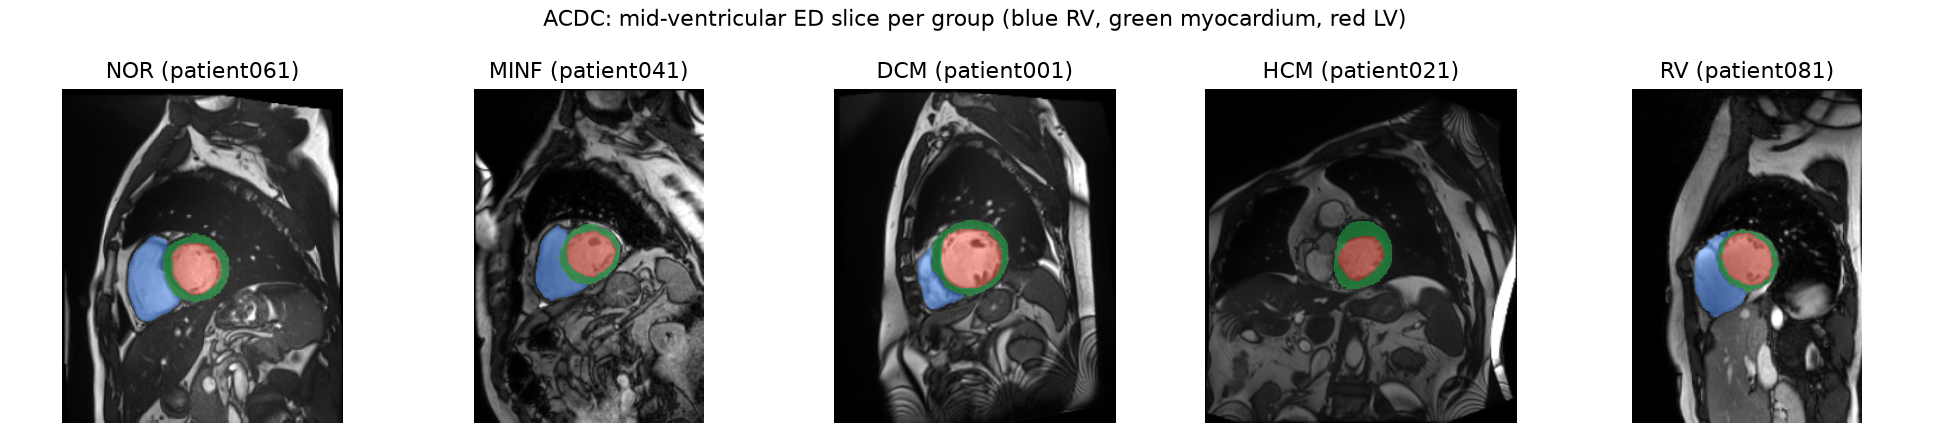

In [4]:
ds = jload("data_summary.json")
display(pd.DataFrame(ds["per_group"]).T.rename_axis("split"))
display(pd.DataFrame(ds["per_fold_group"]).T.rename_axis("fold"))
print({k: v for k, v in ds.items() if k not in ("per_group", "per_fold_group")})
meta = pd.read_csv(R / "acdc_meta.csv"); display(meta.head())
fig("fig_examples.png")

## 3. Level 1: classical segmentation baseline (per-pixel LightGBM)

The classical approach to segmentation without deep learning is a per-pixel classifier on hand-crafted filter
features (as in the ilastik tool): for every pixel, Gaussian-smoothed intensity, gradient magnitude and Hessian
eigenvalues at 6 scales (0.5-16 px), plus position (offset from the image centre and relative slice position):
27 features. A gradient-boosted tree model (LightGBM) predicts background / RV / MYO / LV.

Choices: class-balanced pixel sampling (the heart is ~3% of the image) with a prior correction of the predicted
probabilities back to the true class frequencies; early stopping on 8 patients held out *inside* the training folds;
the same 5 folds and the same post-processing (largest connected component) as the U-Net, so the comparison is fair.

**Tuning** (`acdc/tune_seg_baseline.py`): a 12-configuration grid over the number of leaves, learning rate and
minimum samples per leaf, scored by 5-fold CV on the training patients only (Dice on a random pixel sample of each
held-out volume). The test set is not used for tuning.

In [5]:
show_code('acdc/seg_baseline.py', 'acdc/tune_seg_baseline.py')

**`acdc/seg_baseline.py`**

"""Classical segmentation baseline (CPU): per-pixel LightGBM on hand-crafted multiscale filter features.

Features per pixel (1.25 mm slices): Gaussian-smoothed intensity, gradient magnitude and the two Hessian eigenvalues
at 6 scales (sigma 0.5-16 px, skimage `multiscale_basic_features`, 24 values) + position: row / column offset from the
image centre (mm) and relative slice position in the stack (base 0 -> apex 1). This is the ilastik-style "random forest
pixel classifier" approach, with gradient-boosted trees instead of a random forest.

Protocol = same as the U-Net: for each of the 5 folds, train on the 80 other training patients (8 of them held out for
early stopping), predict the fold's 20 patients (out-of-fold) and the 50 test patients; test = average of the 5 fold
models. Training pixels are sampled class-balanced per slice; predicted probabilities are corrected back to the true
class priors (p_c * prior_true_c / prior_sampled_c, renormalised). Same post-processing as the U-Net (largest component).

    python -m acdc.seg_baseline --threads 6
"""
import argparse
import json
import time

import lightgbm as lgb
import numpy as np
import pandas as pd
import torch
from skimage.feature import multiscale_basic_features

from acdc.common import RESULTS, TARGET_SPACING, WORK
from acdc.predict_seg import finalize, score_and_save

# Setting used for all reported results. tune_seg_baseline.py checked 12 settings by 5-fold CV on the training patients:
# the best (31 leaves, lr 0.1, 200 min samples) was +0.016 sampled Dice, almost all from one fold (within CV noise).
PARAMS = dict(objective="multiclass", num_class=4, learning_rate=0.05, num_leaves=63, min_child_samples=50,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1)


def volume_features(img):
    """(Z,H,W) -> (Z,H,W,27) float32 feature array."""
    Z, H, W = img.shape
    feats = []
    rr, cc = np.meshgrid((np.arange(H) - H / 2) * TARGET_SPACING, (np.arange(W) - W / 2) * TARGET_SPACING, indexing="ij")
    for z in range(Z):
        f = multiscale_basic_features(img[z], intensity=True, edges=True, texture=True, sigma_min=0.5, sigma_max=16,
                                      num_sigma=6)
        pos = np.stack([rr, cc, np.full((H, W), z / max(Z - 1, 1))], -1)
        feats.append(np.concatenate([f, pos], -1).astype(np.float32))
    return np.stack(feats)


def sample_pixels(F, lab, rng, per_class=150):
    """Class-balanced pixel sample from one volume: up to `per_class` pixels of each class per slice."""
    X, y = [], []
    for z in range(lab.shape[0]):
        for c in range(4):
            idx = np.flatnonzero(lab[z] == c)
            if len(idx):
                pick = rng.choice(idx, min(per_class, len(idx)), replace=False)
                X.append(F[z].reshape(-1, F.shape[-1])[pick]); y.append(np.full(len(pick), c))
    return np.concatenate(X), np.concatenate(y)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--threads", type=int, default=6)
    args = ap.parse_args()
    name = "classical_lgbm"
    (WORK / "preds" / name).mkdir(parents=True, exist_ok=True)
    (RESULTS / "seg").mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    rng = np.random.default_rng(42)
    t0 = time.time()

    # 1) features + class-balanced pixel samples for every training volume (cached in memory), true class frequencies
    samples, counts = {}, np.zeros(4)
    for r in meta[meta.split == "train"].itertuples():
        d = np.load(WORK / "cache" / f"{r.pid}.npz")
        for ph in ("ED", "ES"):
            lab = d[f"lab_{ph}"]
            samples[(r.pid, ph)] = sample_pixels(volume_features(d[f"img_{ph}"].astype(np.float32)), lab, rng)
            counts += np.bincount(lab.ravel(), minlength=4)
    print(f"features + samples: {(time.time() - t0) / 60:.1f} min", flush=True)

    # 2) one model per fold
    models, info = [], []
    for f in range(5):
        tr = meta[(meta.sp

**`acdc/tune_seg_baseline.py`**

"""Hyper-parameter tuning of the classical segmentation baseline (per-pixel LightGBM, see seg_baseline.py).

Grid: num_leaves {31, 63, 255} x learning_rate {0.05, 0.1} x min_child_samples {50, 200} = 12 configurations
(the original setting 63 / 0.05 / 50 is one of them). Everything else as in seg_baseline.py.

Protocol (training patients only, the test set is never used):
  the frozen 5 folds; for each fold, train on the other 80 patients (8 of them for early stopping, as in
  seg_baseline.py) and score the fold's 20 patients (40 volumes).
Score: Dice of RV, MYO and LV estimated on a uniform random sample of 30,000 pixels per volume (prior-corrected
  argmax, no post-processing), averaged over structures and volumes. Predicting every pixel of every volume would take
  ~2 h per configuration; the pixel sample keeps the TP/FP/FN proportions, so it ranks configurations the same way.
Note: choosing the configuration by this CV makes the baseline's CV numbers slightly optimistic; its test numbers stay
  clean.

Output: results/seg/classical_lgbm_tuning.csv (one row per configuration and fold) and
        results/seg/classical_lgbm_tuning_best.json (best configuration, read by seg_baseline.py --params).

    python -m acdc.tune_seg_baseline --threads 6
"""
import argparse
import itertools
import json
import time
import zlib

import lightgbm as lgb
import numpy as np
import pandas as pd

from acdc.common import RESULTS, WORK
from acdc.seg_baseline import PARAMS, sample_pixels, volume_features

N_UNIFORM = 30000


def dice_from_sample(pred, lab):
    """Mean Dice over classes 1-3 (RV, MYO, LV) from sampled pixels; a class absent in both counts as 1."""
    d = []
    for c in (1, 2, 3):
        p, t = pred == c, lab == c
        d.append(1.0 if p.sum() + t.sum() == 0 else 2 * (p & t).sum() / (p.sum() + t.sum()))
    return float(np.mean(d))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--threads", type=int, default=6)
    args = ap.parse_args()
    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    train = meta[meta.split == "train"]
    rng = np.random.default_rng(42)  # same seed and sampling order as seg_baseline.py for the balanced samples
    t0 = time.time()

    # 1) features once per volume: balanced training sample (as in seg_baseline) + uniform scoring sample
    bal, uni, counts = {}, {}, np.zeros(4)
    for r in train.itertuples():
        d = np.load(WORK / "cache" / f"{r.pid}.npz")
        for ph in ("ED", "ES"):
            lab = d[f"lab_{ph}"]
            F = volume_features(d[f"img_{ph}"].astype(np.float32))
            bal[(r.pid, ph)] = sample_pixels(F, lab, rng)
            counts += np.bincount(lab.ravel(), minlength=4)
            idx = np.random.default_rng(zlib.crc32(f"{r.pid}_{ph}".encode())).choice(  # reproducible per volume
                lab.size, min(N_UNIFORM, lab.size), replace=False)
            uni[(r.pid, ph)] = (F.reshape(-1, F.shape[-1])[idx], lab.ravel()[idx])
    prior_true = counts / counts.sum()
    print(f"features: {(time.time() - t0) / 60:.1f} min", flush=True)

    # same early-stopping patients per fold for every configuration
    es_pat = {f: rng.choice(train[train.fold != f].pid.tolist(), 8, replace=False).tolist() for f in range(5)}
    out_csv = RESULTS / "seg" / "classical_lgbm_tuning.csv"
    rows = []
    grid = list(itertools.product([31, 63, 255], [0.05, 0.1], [50, 200]))
    for leaves, lr, mcs in grid:
        params = {**PARAMS, "num_leaves": leaves, "learning_rate": lr, "min_child_samples": mcs, "num_threads": args.threads}
        for f in range(5):
            t = time.time()
            fit = [p for p in train[train.fold != f].pid if p not in es_pat[f]]
            stack = lambda pids: [np.concatenate(z) for z in zip(*[bal[(p, ph)] for p in pids for ph in ("ED", "ES")])]  # noqa: E731
            (Xa, ya), (Xe, ye) = stack(fit), stack(es_pat[f])
            prior_sampled = np.bincount(ya, minlength=4) / len(ya)
            m = lgb.train(params, lgb.D

In [6]:
if RUN["tune_baseline"]:
    run("python -m acdc.tune_seg_baseline --threads 6")
if RUN["seg_baseline"]:
    run("python -m acdc.seg_baseline --threads 6")

In [7]:
p = R / "seg" / "classical_lgbm_tuning.csv"
if p.exists():
    t = pd.read_csv(p)
    display(t.groupby(["num_leaves", "learning_rate", "min_child_samples"])
             .agg(cv_dice=("dice_sampled", "mean"), sd_over_folds=("dice_sampled", "std"), mean_trees=("best_iter", "mean"))
             .sort_values("cv_dice", ascending=False))
    b = R / "seg" / "classical_lgbm_tuning_best.json"
    if b.exists():
        print(json.dumps(json.loads(b.read_text()), indent=1))
info = jload("seg/classical_lgbm_info.json")
print("parameters used for the reported baseline:", info["params"])
print("trees per fold (early stopping):", [f["best_iter"] for f in info["folds"]])

cv_dice  sd_over_folds  mean_trees
num_leaves learning_rate min_child_samples                                    
31         0.10          200                  0.650          0.029       266.8
           0.05          50                   0.648          0.032       466.0
                         200                  0.647          0.033       422.4
           0.10          50                   0.646          0.035       220.0
63         0.10          50                   0.641          0.026       132.0
           0.05          200                  0.640          0.027       261.2
           0.10          200                  0.639          0.027       139.4
           0.05          50                   0.635          0.027       272.0
255        0.05          200                  0.627          0.040       134.6
                         50                   0.627          0.034       130.8
           0.10          50                   0.620          0.041        64.4
                         200                  0.617          0.039        62.2

{
 "params": {
  "objective": "multiclass",
  "num_class": 4,
  "learning_rate": 0.1,
  "num_leaves": 31,
  "min_child_samples": 200,
  "feature_fraction": 0.8,
  "bagging_fraction": 0.8,
  "bagging_freq": 1,
  "lambda_l2": 1.0,
  "verbose": -1
 },
 "cv_dice_sampled": 0.6503631012267297,
 "cv_dice_sampled_sd_over_folds": 0.028753829773537635,
 "original_cv_dice_sampled": 0.6345093302785118,
 "n_configs": 12,
 "minutes": 58.53128480911255
}
parameters used for the reported baseline: {'objective': 'multiclass', 'num_class': 4, 'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 50, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 1.0, 'verbose': -1}
trees per fold (early stopping): [345, 168, 104, 584, 159]


## 4. Level 2: U-Net segmentation

A 2D U-Net following the nnU-Net recipe (the strongest published approach on ACDC): 7 resolution stages,
32-512 channels, instance normalisation, LeakyReLU, deep supervision; loss = Dice + cross-entropy; SGD with Nesterov
momentum, learning rate 0.01 with polynomial decay; 250 epochs x 250 iterations x 32 patches of 256x256; bf16 mixed
precision. Data augmentation on the GPU: rotation, scaling, mirroring, Gaussian noise, blur, brightness, contrast,
simulated low resolution, gamma. No checkpoint selection on validation data (the last epoch is used), so the
out-of-fold predictions are honest.

Prediction: 5 fold models (test = ensemble of all 5), mirroring test-time augmentation, back to the original grid,
largest connected component per structure. Uncertainty: entropy of the predicted probabilities and disagreement
between the fold models.

Ablations (same code, one flag each): 2.5D input (3 neighbouring slices), cross-entropy only, no augmentation,
no test-time augmentation, no post-processing.

In [8]:
show_code('acdc/unet.py', 'acdc/augment.py', 'acdc/train_seg.py', 'acdc/predict_seg.py', 'acdc/run_queue.sh')

**`acdc/unet.py`**

"""2D U-Net following the nnU-Net recipe (Isensee et al., Nature Methods 2021), written out so it can be explained.

encoder: 7 stages, each = 2 x (3x3 conv -> InstanceNorm -> LeakyReLU); stage s>0 starts with a stride-2 conv.
         channels 32, 64, 128, 256, 512, 512, 512  (a 256x256 patch ends at 4x4).
decoder: transposed conv (x2 upsampling) -> concatenate the encoder features of the same size -> 2 conv blocks.
deep supervision: a 1x1 conv head on the 5 highest-resolution decoder outputs; the loss is computed at every one of
         them (targets downsampled), weighted 1, 1/2, 1/4, ... This helps gradients reach the deep layers.
in_ch > 1 = 2.5D input (neighbouring slices as extra channels).
"""
import torch
import torch.nn as nn


class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout, stride=1):
        super().__init__(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=True),
            nn.InstanceNorm2d(cout, affine=True),
            nn.LeakyReLU(0.01, inplace=True),
        )


class Stage(nn.Sequential):
    def __init__(self, cin, cout, stride):
        super().__init__(ConvBlock(cin, cout, stride), ConvBlock(cout, cout))


class UNet2D(nn.Module):
    def __init__(self, in_ch=1, n_classes=4, features=(32, 64, 128, 256, 512, 512, 512), n_heads=5):
        super().__init__()
        self.enc = nn.ModuleList()
        c = in_ch
        for i, f in enumerate(features):
            self.enc.append(Stage(c, f, stride=1 if i == 0 else 2))
            c = f
        self.up, self.dec, self.heads = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for f_skip in reversed(features[:-1]):  # from deepest to shallowest
            self.up.append(nn.ConvTranspose2d(c, f_skip, 2, stride=2))
            self.dec.append(Stage(2 * f_skip, f_skip, stride=1))
            self.heads.append(nn.Conv2d(f_skip, n_classes, 1))
            c = f_skip
        self.n_heads = n_heads
        self.deep_supervision = True  # switched off at inference: only the full-resolution output is returned

    def forward(self, x):
        skips = []
        for st in self.enc:
            x = st(x)
            skips.append(x)
        x = skips.pop()
        outs = []
        for up, dec, head in zip(self.up, self.dec, self.heads):
            x = dec(torch.cat([up(x), skips.pop()], 1))
            outs.append(head(x))
        if not self.deep_supervision:
            return outs[-1]
        return outs[::-1][: self.n_heads]  # full resolution first


def n_params(model):
    return sum(p.numel() for p in model.parameters())


if __name__ == "__main__":
    m = UNet2D()
    y = m(torch.randn(2, 1, 256, 256))
    print([t.shape for t in y], f"{n_params(m) / 1e6:.1f} M params")

**`acdc/augment.py`**

"""GPU data sampling + augmentation for 2D segmentation training (nnU-Net-style, simplified).

All training slices live on the GPU as a (N, C, 400, 400) canvas (1.25 mm pixels, heart roughly central). A batch is made
by one `grid_sample` call that crops a 256x256 patch and applies rotation / scaling / mirroring at the same time, then
intensity augmentations are applied per sample. Probabilities follow nnU-Net's defaults.
"""
import math

import torch
import torch.nn.functional as F

CANVAS = 400
PATCH = 256


def to_canvas(vol: torch.Tensor, value: float, size=CANVAS) -> torch.Tensor:
    """Centre a (..., H, W) tensor on a size x size canvas (pad with `value`, or centre-crop if larger)."""
    H, W = vol.shape[-2:]
    out = torch.full((*vol.shape[:-2], size, size), value, dtype=vol.dtype)
    ys, xs = max(0, (H - size) // 2), max(0, (W - size) // 2)  # crop offsets (if larger)
    yd, xd = max(0, (size - H) // 2), max(0, (size - W) // 2)  # paste offsets (if smaller)
    h, w = min(H, size), min(W, size)
    out[..., yd:yd + h, xd:xd + w] = vol[..., ys:ys + h, xs:xs + w]
    return out


def neighbour_stack(vol: torch.Tensor, in_ch: int) -> torch.Tensor:
    """(Z,H,W) -> (Z,in_ch,H,W): slice z plus its neighbours (edge slices repeated). in_ch=1 is plain 2D."""
    k = in_ch // 2
    idx = torch.arange(vol.shape[0])
    return torch.stack([vol[(idx + d).clamp(0, vol.shape[0] - 1)] for d in range(-k, k + 1)], 1)


def _gaussian_blur(x, sigma):
    """Blur one sample (C,H,W) with a separable Gaussian of std `sigma` pixels."""
    r = max(1, int(math.ceil(3 * sigma)))
    t = torch.arange(-r, r + 1, device=x.device, dtype=x.dtype)
    k = torch.exp(-0.5 * (t / sigma) ** 2)
    k = k / k.sum()
    C = x.shape[0]
    x = F.conv2d(F.pad(x[None], (r, r, 0, 0), mode="reflect"), k.view(1, 1, 1, -1).repeat(C, 1, 1, 1), groups=C)
    x = F.conv2d(F.pad(x, (0, 0, r, r), mode="reflect"), k.view(1, 1, -1, 1).repeat(C, 1, 1, 1), groups=C)
    return x[0]


class Sampler:
    def __init__(self, imgs, labs, device, augment=True, fg_prob=1 / 3):
        """imgs: (N,C,400,400) float16, labs: (N,400,400) uint8 (CPU tensors)."""
        self.imgs, self.labs = imgs.to(device), labs.to(device)
        self.device, self.augment, self.fg_prob = device, augment, fg_prob
        # foreground pixel coordinates of every slice, used to centre 1/3 of the patches on the heart (class balance)
        self.fg = [torch.nonzero(l > 0) for l in self.labs]
        self.has_fg = torch.tensor([len(f) > 0 for f in self.fg])

    def batch(self, B):
        dev = self.device
        idx = torch.randint(len(self.imgs), (B,))
        # patch centres in canvas pixel coordinates
        centre = torch.empty(B, 2)
        for b in range(B):
            i = int(idx[b])
            if torch.rand(1) < self.fg_prob and self.has_fg[i]:
                centre[b] = self.fg[i][torch.randint(len(self.fg[i]), (1,))].float().cpu()[0]
            else:
                centre[b] = torch.rand(2) * (CANVAS - PATCH) + PATCH / 2
        # affine map from output patch coordinates ([-1,1]) to canvas coordinates ([-1,1])
        A = torch.eye(2).repeat(B, 1, 1) * (PATCH / CANVAS)
        if self.augment:
            rot = torch.rand(B) < 0.2
            ang = torch.where(rot, (torch.rand(B) * 2 - 1) * math.pi, torch.zeros(B))
            sc = torch.where(torch.rand(B) < 0.2, 0.7 + 0.7 * torch.rand(B), torch.ones(B))  # zoom 0.7-1.4
            R = torch.stack([torch.stack([ang.cos(), -ang.sin()], -1), torch.stack([ang.sin(), ang.cos()], -1)], 1)
            A = A @ R / sc[:, None, None]
            flip = torch.where(torch.rand(B, 2) < 0.5, -1.0, 1.0)  # mirror each axis with p=0.5
            A = A * flip[:, None, :]
        # grid_sample's (x, y) = (last dim, second-to-last dim); centre is (row, col)
        t = (2 * torch.stack([centre[:, 1], centre[:, 0]], 1) + 1) / CANVAS - 1  # pixel -> normalised (align_corners=False)
        theta = torch.cat([A, t[:, :, None]], 2).to(dev)
        i

**`acdc/train_seg.py`**

"""Step 2 - train the 2D U-Net on one cross-validation fold.

    python -m acdc.train_seg --cfg unet2d --fold 0              # main configuration
    python -m acdc.train_seg --cfg unet25d --in_ch 3 --fold 0   # 2.5D ablation (3 neighbouring slices as input)
    python -m acdc.train_seg --cfg unet2d_ce --loss ce --fold 0 # loss ablation (cross-entropy only)
    python -m acdc.train_seg --cfg unet2d_noaug --aug none ...  # augmentation ablation

Training set = the 80 training patients outside the fold (ED + ES slices); the 20 patients of the fold are the
validation set. The test patients (101-150) are never loaded here. Recipe (nnU-Net defaults): Dice + cross-entropy loss
with deep supervision, SGD (Nesterov, momentum 0.99), lr 0.01 with polynomial decay, 250 iterations per epoch, batch 32
patches of 256x256. The model of the LAST epoch is kept (no checkpoint picking on the validation fold, so the validation
fold stays an honest out-of-fold estimate).
"""
import argparse
import json
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from acdc.augment import Sampler, neighbour_stack, to_canvas
from acdc.common import CLASSES, RESULTS, WORK, dice, set_seed
from acdc.infer import predict_volume
from acdc.unet import UNet2D, n_params


def load_patients(pids):
    """Returns per-volume list of (img (Z,H,W) float tensor, lab (Z,H,W) uint8 tensor) for ED and ES."""
    vols = []
    for pid in pids:
        d = np.load(WORK / "cache" / f"{pid}.npz")
        for ph in ("ED", "ES"):
            vols.append((pid, ph, torch.from_numpy(d[f"img_{ph}"].astype(np.float32)), torch.from_numpy(d[f"lab_{ph}"])))
    return vols


def dc_ce_loss(logits, target, use_dice=True):
    """Cross-entropy + soft Dice over the 3 foreground classes, Dice computed over the whole batch ("batch Dice")."""
    ce = F.cross_entropy(logits, target)
    if not use_dice:
        return ce
    p = torch.softmax(logits.float(), 1)[:, 1:]
    oh = F.one_hot(target, 4).permute(0, 3, 1, 2)[:, 1:].float()
    inter = (p * oh).sum((0, 2, 3))
    den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return ce + (1 - (2 * inter + 1e-5) / (den + 1e-5)).mean()


def deep_supervision_loss(outs, target, use_dice):
    w = torch.tensor([1 / 2 ** i for i in range(len(outs))])
    w = w / w.sum()
    loss = 0
    for wi, o in zip(w, outs):
        t = target if o.shape[-1] == target.shape[-1] else \
            F.interpolate(target[:, None].float(), size=o.shape[-2:], mode="nearest")[:, 0].long()
        loss = loss + wi * dc_ce_loss(o, t, use_dice)
    return loss


@torch.no_grad()
def validate(model, vols, in_ch):
    """Mean Dice per structure over validation volumes, at 1.25 mm (monitoring only; final metrics use the original grid)."""
    model.deep_supervision = False
    model.eval()
    torch.backends.cudnn.benchmark = False  # every volume has another size: don't re-benchmark kernels for each
    d = {n: [] for n in CLASSES.values()}
    for _, _, img, lab in vols:
        seg = predict_volume(model, img, in_ch, tta=False).argmax(1).numpy()
        for c, n in CLASSES.items():
            d[n].append(dice(seg == c, lab.numpy() == c))
    model.deep_supervision = True
    model.train()
    torch.backends.cudnn.benchmark = True
    return {n: float(np.mean(v)) for n, v in d.items()}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cfg", default="unet2d")
    ap.add_argument("--fold", type=int, required=True)
    ap.add_argument("--in_ch", type=int, default=1)
    ap.add_argument("--loss", choices=["dce", "ce"], default="dce")
    ap.add_argument("--aug", choices=["full", "none"], default="full")
    ap.add_argument("--epochs", type=int, default=250)  # all reported models: 250
    ap.add_argument("--iters", type=int, default=250)
    ap.add_argument("--bs", type=int, default=32)
    ap.add_argument("--lr", type=float, default=0.01)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--val_

**`acdc/predict_seg.py`**

"""Step 3 - predict segmentations for all 150 patients with one trained configuration and score them.

    python -m acdc.predict_seg --cfg unet2d

Protocol (no test-set leakage):
  training patients 001-100: out-of-fold prediction, i.e. by the model of the fold the patient was held out in;
  test patients 101-150:     average of the 5 fold models' softmax outputs (ensemble).
Both use mirroring test-time augmentation (4 flips) unless --no_tta. Probabilities (1.25 mm) are resampled to the
original grid, argmax'ed, and each structure is reduced to its largest connected component.

Writes WORK/preds/<cfg>/<pid>.npz (seg_ED, seg_ES on the original grid, uint8; per-slice mean predictive entropy) and
results/seg/<cfg>_metrics.csv (one row per patient x phase: Dice, HD, HD95, ASSD per structure + uncertainty summaries).
"""
import argparse
import time

import numpy as np
import pandas as pd
import torch

from acdc.common import CLASSES, RESULTS, WORK, keep_largest_component, load_phase, probs_to_original, read_info, seg_metrics
from acdc.infer import load_model, predict_volume


def entropy(p: torch.Tensor) -> torch.Tensor:
    """Predictive entropy per pixel of (Z,C,H,W) probabilities, normalised to [0,1] by log(C)."""
    return -(p.clamp_min(1e-8).log() * p).sum(1) / np.log(p.shape[1])


def finalize(prob_r: torch.Tensor, orig_xy, postprocess=True):
    """1.25 mm probabilities -> (segmentation on the original grid, entropy map on the original grid)."""
    p = probs_to_original(prob_r.float(), orig_xy)
    seg = p.argmax(1).numpy().astype(np.uint8)
    if postprocess:
        seg = keep_largest_component(seg)
    return seg, entropy(p).numpy().astype(np.float16)


def uncertainty_summary(seg, ent, member_segs=None):
    """Volume-level uncertainty scores used for failure detection:
    ent_fg   mean entropy inside the (dilated) predicted heart region,
    disagree fraction of predicted-heart voxels on which ensemble members / TTA variants disagree (if available)."""
    from scipy import ndimage
    heart = ndimage.binary_dilation(seg > 0, iterations=3)
    out = {"ent_fg": float(ent[heart].mean()) if heart.any() else float("nan")}
    if member_segs is not None:
        stack = np.stack(member_segs)
        dis = (stack != stack[0:1]).any(0)
        out["disagree"] = float(dis[heart].mean()) if heart.any() else float("nan")
    return out


def score_and_save(cfg, pid, phase_out, meta_row, extra=None):
    """phase_out: {'ED': (seg, ent, member_segs), 'ES': ...}. Saves the npz and returns metric rows."""
    rows, arrays = [], {}
    for ph, (seg, ent, members) in phase_out.items():
        _, gt, sp = load_phase(pid, ph)
        arrays[f"seg_{ph}"] = seg
        arrays[f"ent_slice_{ph}"] = ent.reshape(ent.shape[0], -1).mean(1)
        r = {"pid": pid, "phase": ph, "split": meta_row.split, "group": meta_row.group, "fold": meta_row.fold,
             **seg_metrics(seg, gt, sp), **uncertainty_summary(seg, ent, members)}
        if extra:
            r.update(extra)
        rows.append(r)
    np.savez_compressed(WORK / "preds" / cfg / f"{pid}.npz", **arrays)
    return rows


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cfg", default="unet2d")
    ap.add_argument("--no_tta", action="store_true")
    ap.add_argument("--no_pp", action="store_true", help="no largest-connected-component post-processing")
    ap.add_argument("--out", default=None, help="name for outputs (default: cfg, + suffixes)")
    args = ap.parse_args()
    name = args.out or args.cfg + ("_notta" if args.no_tta else "") + ("_nopp" if args.no_pp else "")
    # Mirroring TTA is only valid for models trained with mirroring augmentation: a model trained without
    # augmentation has never seen flipped hearts (RV on the other side) and its flipped predictions are wrong.
    trained_aug = load_model(WORK / "runs" / f"{args.cfg}_f0" / "model.pt", "cpu")[1]["args"]["aug"]
    if trained_aug == "none" and not args.no_tta:
        print("model train

**`acdc/run_queue.sh`**

#!/usr/bin/env bash
# GPU job queue: runs the commands in $QUEUE one after another (the GPU is saturated by one job, so no parallel runs).
# Lines can be appended to the queue file while it runs; finished lines are recorded in $QUEUE.done.
# Usage: QUEUE=/path/queue.txt acdc/run_queue.sh     (run inside tmux)
set -u
QUEUE=${QUEUE:-$HOME/data/acdc/work/queue.txt}
LOGDIR=${LOGDIR:-$HOME/data/acdc/work/logs}
mkdir -p "$LOGDIR"; touch "$QUEUE.done"
cd "$(dirname "$0")/.."
while true; do
  next=$(grep -vxF -f "$QUEUE.done" "$QUEUE" | grep -v '^\s*#' | grep -v '^\s*$' | head -n 1)
  if [ -z "$next" ]; then sleep 30; continue; fi
  name=$(echo "$next" | tr -c 'A-Za-z0-9_' '_' | cut -c1-120)
  echo "$(date '+%F %T') START $next"
  bash -c "$next" > "$LOGDIR/$name.log" 2>&1
  echo "$(date '+%F %T') EXIT $? $next"
  echo "$next" >> "$QUEUE.done"
done

In [9]:
if RUN["train_unet"]:
    for f in range(5):
        run(f"python -m acdc.train_seg --cfg unet2d --fold {f} --epochs 250")                # main model
        run(f"python -m acdc.train_seg --cfg unet25d --fold {f} --epochs 250 --in_ch 3")     # ablation: 2.5D
        run(f"python -m acdc.train_seg --cfg unet2d_ce --fold {f} --epochs 250 --loss ce")   # ablation: CE only
        run(f"python -m acdc.train_seg --cfg unet2d_noaug --fold {f} --epochs 250 --aug none")  # ablation: no aug
if RUN["predict_unet"]:
    run("python -m acdc.predict_seg --cfg unet2d")
    run("python -m acdc.predict_seg --cfg unet2d --no_tta")   # ablation: no test-time augmentation
    run("python -m acdc.predict_seg --cfg unet2d --no_pp")    # ablation: no post-processing
    for c in ("unet25d", "unet2d_ce", "unet2d_noaug"):
        run(f"python -m acdc.predict_seg --cfg {c}")

/tmp/ipykernel_316294/626157154.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax[1].plot(v.epoch, v[["val_dice_RV", "val_dice_MYO", "val_dice_LV"]].mean(1), label=f"fold {f}")
/tmp/ipykernel_316294/626157154.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax[1].plot(v.epoch, v[["val_dice_RV", "val_dice_MYO", "val_dice_LV"]].mean(1), label=f"fold {f}")
/tmp/ipykernel_316294/626157154.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax[1].plot(v.epoch, v[["val_dice_RV", "val_dice_MYO", "val_dice_LV"]].mean(1), label=f"fold {f}")
/tmp/ipykernel_316294/626157154.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  ax[1].plot(v.epoch, v[["val_dice_RV", "val_dice_MYO", "val_dice_LV"]].mean(1), label=f"fold {f}")
/tmp/ipykernel_316294/626157154.py:8: Pandas4Warning: Starting with pandas v

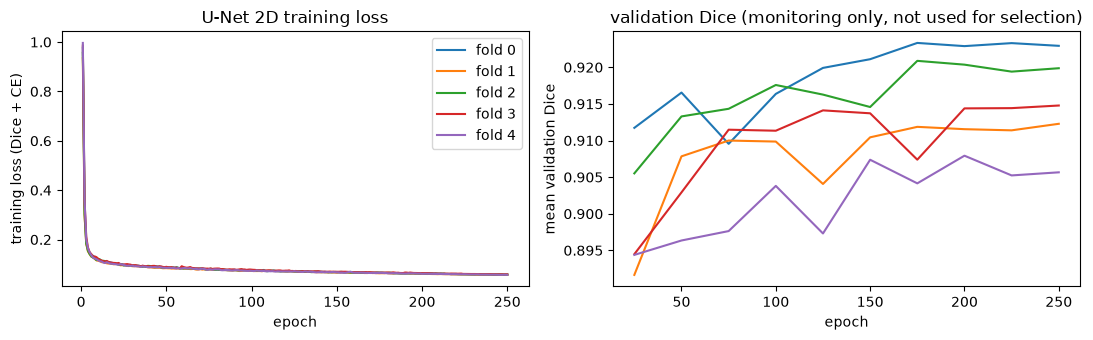

In [10]:
# training curves (fold logs written by train_seg.py)
import matplotlib.pyplot as plt
fig_, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for f in range(5):
    d = pd.read_csv(R / "seg_runs" / f"unet2d_f{f}.csv")
    ax[0].plot(d.epoch, d.loss, label=f"fold {f}")
    v = d.dropna(subset=["val_dice_LV"])
    ax[1].plot(v.epoch, v[["val_dice_RV", "val_dice_MYO", "val_dice_LV"]].mean(1), label=f"fold {f}")
ax[0].set(xlabel="epoch", ylabel="training loss (Dice + CE)", title="U-Net 2D training loss")
ax[1].set(xlabel="epoch", ylabel="mean validation Dice", title="validation Dice (monitoring only, not used for selection)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 5. Segmentation results (H1, ablations) and error propagation into clinical indices (H2)

Metrics: Dice (overlap), HD95 (95th percentile Hausdorff distance, mm: boundary errors), with 95% bootstrap
confidence intervals over patients; paired Wilcoxon tests between models on per-patient mean Dice. Clinical
agreement: Pearson r, Bland-Altman bias and 95% limits of agreement, mean absolute error of each index.

In [11]:
show_code('acdc/evaluate_seg.py')

**`acdc/evaluate_seg.py`**

"""Step 6 - segmentation evaluation across configurations (tables + figures in results/seg/).

    python -m acdc.evaluate_seg --cfgs classical_lgbm unet2d unet25d unet2d_noaug unet2d_ce unet2d_notta unet2d_nopp

Uses results/seg/<cfg>_metrics.csv (from predict_seg / seg_baseline) and the saved predictions.
  seg_summary.csv        mean (95% bootstrap CI over patients) Dice / HD95 / ASSD per structure, phase, eval set
  seg_paired_tests.csv   Wilcoxon signed-rank test, reference config vs every other (per-patient mean Dice / HD95)
  clinical_agreement.csv Pearson r, bias, 95% limits of agreement, mean absolute error of clinical indices vs ground truth
  slice_position.csv     Dice per structure for basal / mid / apical thirds of the heart (slice 0 = base in ACDC)
  dice_by_group.csv      mean Dice per diagnostic group
  uncertainty.csv        how well volume-level uncertainty flags poor segmentations (Spearman, AUROC, Dice after
                         discarding the most uncertain 10/20/30%)
"""
import argparse
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

from acdc.common import CLASSES, GROUPS, RESULTS, WORK, dice, load_phase
from acdc.features import feature_table

OUT = RESULTS / "seg"
STRUCT = list(CLASSES.values())
INDICES = ["LV_EDV", "LV_ESV", "LV_EF", "RV_EDV", "RV_ESV", "RV_EF", "MYO_mass"]
UNITS = {"LV_EDV": "mL", "LV_ESV": "mL", "LV_EF": "%", "RV_EDV": "mL", "RV_ESV": "mL", "RV_EF": "%", "MYO_mass": "g"}


def boot_ci(x, n=2000, seed=0):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng(seed)
    means = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


def summary(dfs):
    rows = []
    for cfg, df in dfs.items():
        for ev, de in (("cv", df[df.split == "train"]), ("test", df[df.split == "test"])):
            for ph in ("ED", "ES"):
                d = de[de.phase == ph]
                for s in STRUCT:
                    r = {"cfg": cfg, "eval": ev, "phase": ph, "structure": s}
                    for met in ("dice", "hd95", "hd", "assd"):
                        m, lo, hi = boot_ci(d[f"{met}_{s}"])
                        r.update({met: m, f"{met}_lo": lo, f"{met}_hi": hi})
                    r["n_failed"] = int(d[f"hd_{s}"].isna().sum())  # empty prediction for this structure
                    rows.append(r)
    return pd.DataFrame(rows)


def per_patient(df, met):
    cols = [f"{met}_{s}" for s in STRUCT]
    return df.groupby("pid")[cols].mean().mean(axis=1)


def paired_tests(dfs, ref):
    rows = []
    for cfg, df in dfs.items():
        if cfg == ref:
            continue
        for ev in ("train", "test"):
            a, b = dfs[ref][dfs[ref].split == ev], df[df.split == ev]
            for met in ("dice", "hd95"):
                x, y = per_patient(a, met), per_patient(b, met).reindex(per_patient(a, met).index)
                ok = np.isfinite(x) & np.isfinite(y)
                w = stats.wilcoxon(x[ok], y[ok])
                rows.append({"ref": ref, "other": cfg, "eval": "cv" if ev == "train" else "test", "metric": met,
                             "ref_mean": x[ok].mean(), "other_mean": y[ok].mean(), "diff": (x[ok] - y[ok]).mean(),
                             "n": int(ok.sum()), "wilcoxon_p": w.pvalue})
    return pd.DataFrame(rows)


def clinical(cfgs):
    gt = feature_table("gt").set_index("pid")
    rows = []
    for cfg in cfgs:
        pr = feature_table(cfg).set_index("pid").loc[gt.index]
        for ev in ("train", "test"):
            m = gt.split == ev
            for k in INDICES:
                a, b = gt.loc[m, k], pr.loc[m, k]
                d = b - a
                rows.append({"cfg": cfg, "eval": "cv" if ev == "train" else "test", "index": k, "unit": UNITS[k],
                             "pearson_r": 

In [12]:
s = pd.read_csv(R / "seg" / "seg_summary.csv")
for ev in ("test", "cv"):
    t = s[s["eval"] == ev].assign(col=lambda d: d.phase + " " + d.structure)
    dice = t.pivot(index="cfg", columns="col", values="dice"); dice["mean Dice"] = dice.mean(1)
    hd = t.pivot(index="cfg", columns="col", values="hd95").add_suffix(" HD95")
    display(Markdown(f"**{ev}**: Dice and HD95 (mm)")); display(dice.join(hd).sort_values("mean Dice", ascending=False))
pt = pd.read_csv(R / "seg" / "seg_paired_tests.csv")
display(Markdown("**Paired Wilcoxon tests (per-patient mean Dice)**")); display(pt[pt.metric == "dice"])

/tmp/ipykernel_316294/2311525559.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  dice = t.pivot(index="cfg", columns="col", values="dice"); dice["mean Dice"] = dice.mean(1)


**test**: Dice and HD95 (mm)

col,ED LV,ED MYO,ED RV,ES LV,ES MYO,ES RV,mean Dice,ED LV HD95,ED MYO HD95,ED RV HD95,ES LV HD95,ES MYO HD95,ES RV HD95
cfg,,,,,,,,,,,,,
unet2d_nopp,0.968,0.905,0.953,0.930,0.923,0.891,0.928,2.447,2.235,3.641,3.460,2.836,5.128
unet2d,0.968,0.904,0.953,0.925,0.923,0.891,0.928,2.219,2.641,3.638,4.076,2.847,5.128
unet2d_notta,0.968,0.903,0.952,0.923,0.921,0.889,0.926,2.227,2.639,3.488,4.128,2.753,5.315
unet25d,0.968,0.903,0.950,0.919,0.921,0.893,0.926,2.216,2.581,3.750,4.276,3.140,5.120
unet2d_ce,0.968,0.902,0.951,0.919,0.920,0.889,0.925,2.268,2.668,3.386,4.348,3.148,5.375
unet2d_noaug,0.965,0.894,0.937,0.909,0.909,0.880,0.916,2.236,2.547,4.733,5.447,4.129,6.324
classical_lgbm,0.820,0.663,0.582,0.655,0.628,0.484,0.639,12.402,17.017,22.162,19.636,19.128,28.461


/tmp/ipykernel_316294/2311525559.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  dice = t.pivot(index="cfg", columns="col", values="dice"); dice["mean Dice"] = dice.mean(1)


**cv**: Dice and HD95 (mm)

col,ED LV,ED MYO,ED RV,ES LV,ES MYO,ES RV,mean Dice,ED LV HD95,ED MYO HD95,ED RV HD95,ES LV HD95,ES MYO HD95,ES RV HD95
cfg,,,,,,,,,,,,,
unet2d,0.967,0.898,0.943,0.930,0.911,0.877,0.921,2.275,3.060,3.342,3.433,3.784,5.704
unet2d_nopp,0.967,0.901,0.941,0.927,0.911,0.877,0.921,2.397,2.314,4.778,4.708,3.580,6.479
unet25d,0.968,0.898,0.941,0.928,0.911,0.873,0.920,1.826,2.926,3.571,3.168,3.350,5.883
unet2d_ce,0.966,0.896,0.940,0.926,0.908,0.873,0.918,2.216,3.171,3.736,3.677,3.927,5.858
unet2d_notta,0.965,0.893,0.942,0.930,0.908,0.871,0.918,2.337,3.183,3.368,3.425,3.698,6.168
unet2d_noaug,0.963,0.881,0.930,0.913,0.896,0.852,0.906,2.025,3.168,4.270,4.617,4.129,6.691
classical_lgbm,0.820,0.640,0.576,0.710,0.625,0.485,0.643,10.434,17.551,22.356,15.260,18.471,26.153


**Paired Wilcoxon tests (per-patient mean Dice)**

,ref,other,eval,metric,ref_mean,other_mean,diff,n,wilcoxon_p
0,unet2d,classical_lgbm,cv,dice,0.921,0.643,2.785e-01,100,3.897e-18
2,unet2d,classical_lgbm,test,dice,0.928,0.639,2.890e-01,50,1.776e-15
4,unet2d,unet25d,cv,dice,0.921,0.920,1.111e-03,100,2.184e-01
6,unet2d,unet25d,test,dice,0.928,0.926,1.761e-03,50,6.780e-02
8,unet2d,unet2d_noaug,cv,dice,0.921,0.906,1.531e-02,100,1.449e-11
10,unet2d,unet2d_noaug,test,dice,0.928,0.916,1.185e-02,50,4.960e-11
12,unet2d,unet2d_ce,cv,dice,0.921,0.918,2.887e-03,100,4.031e-04
14,unet2d,unet2d_ce,test,dice,0.928,0.925,2.588e-03,50,9.469e-05
16,unet2d,unet2d_notta,cv,dice,0.921,0.918,2.921e-03,100,1.308e-10
18,unet2d,unet2d_notta,test,dice,0.928,0.926,1.514e-03,50,1.540e-03


cfg,classical_lgbm,unet25d,unet2d,unet2d_ce,unet2d_noaug,unet2d_nopp,unet2d_notta
index,,,,,,,
LV_EDV,0.645,0.996,0.997,0.996,0.997,0.996,0.997
LV_EF,0.847,0.987,0.989,0.990,0.989,0.991,0.989
LV_ESV,0.821,0.996,0.996,0.997,0.997,0.997,0.997
MYO_mass,0.460,0.987,0.988,0.984,0.984,0.988,0.988
RV_EDV,0.651,0.992,0.994,0.995,0.987,0.994,0.994
RV_EF,0.261,0.877,0.866,0.882,0.884,0.868,0.861
RV_ESV,0.652,0.957,0.960,0.958,0.958,0.960,0.958


,cfg,eval,index,unit,pearson_r,bias,loa_lo,loa_hi,mae
21,unet2d,test,LV_EDV,mL,0.997,-1.403,-13.064,10.259,4.884
22,unet2d,test,LV_ESV,mL,0.996,-0.302,-13.471,12.868,4.989
23,unet2d,test,LV_EF,%,0.989,-0.352,-6.769,6.064,2.387
24,unet2d,test,RV_EDV,mL,0.994,-1.409,-16.049,13.230,5.527
25,unet2d,test,RV_ESV,mL,0.960,-3.371,-31.339,24.596,9.085
26,unet2d,test,RV_EF,%,0.866,1.847,-11.660,15.353,5.163
27,unet2d,test,MYO_mass,g,0.988,4.957,-11.232,21.146,7.535


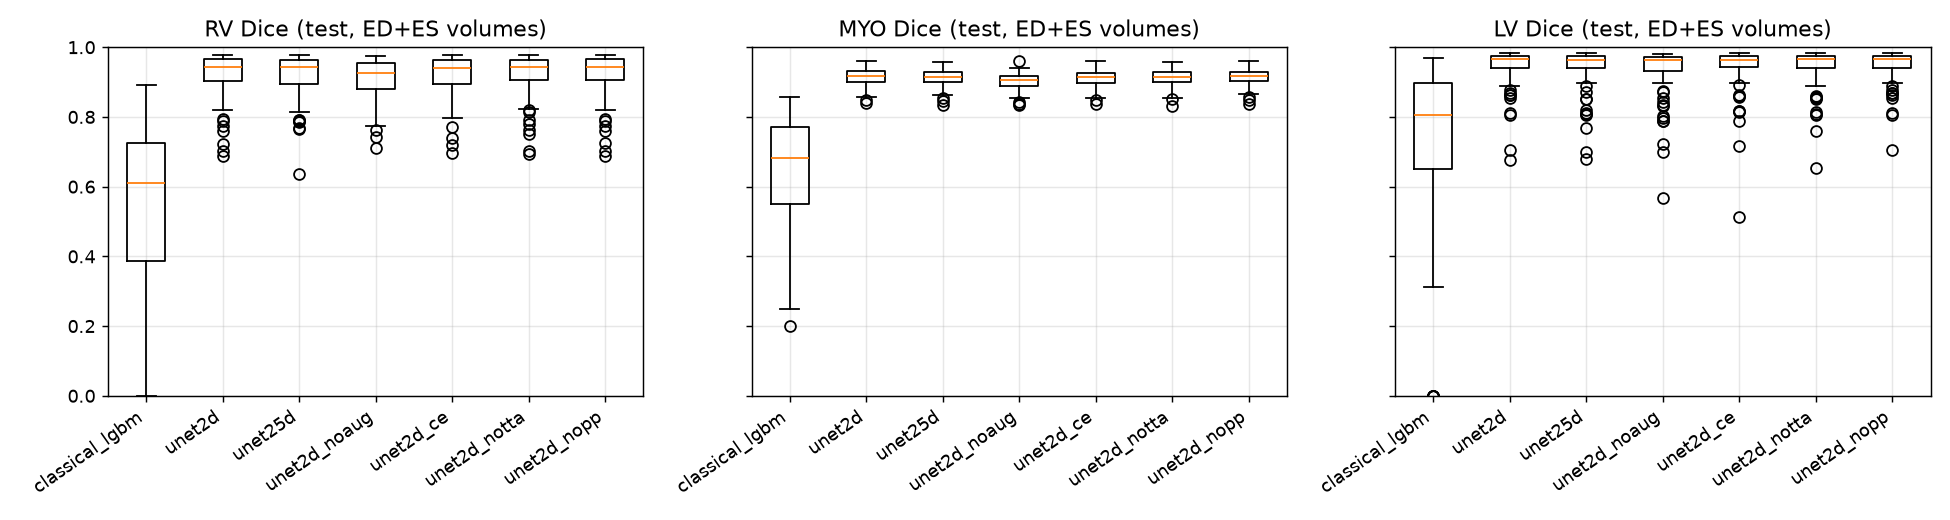

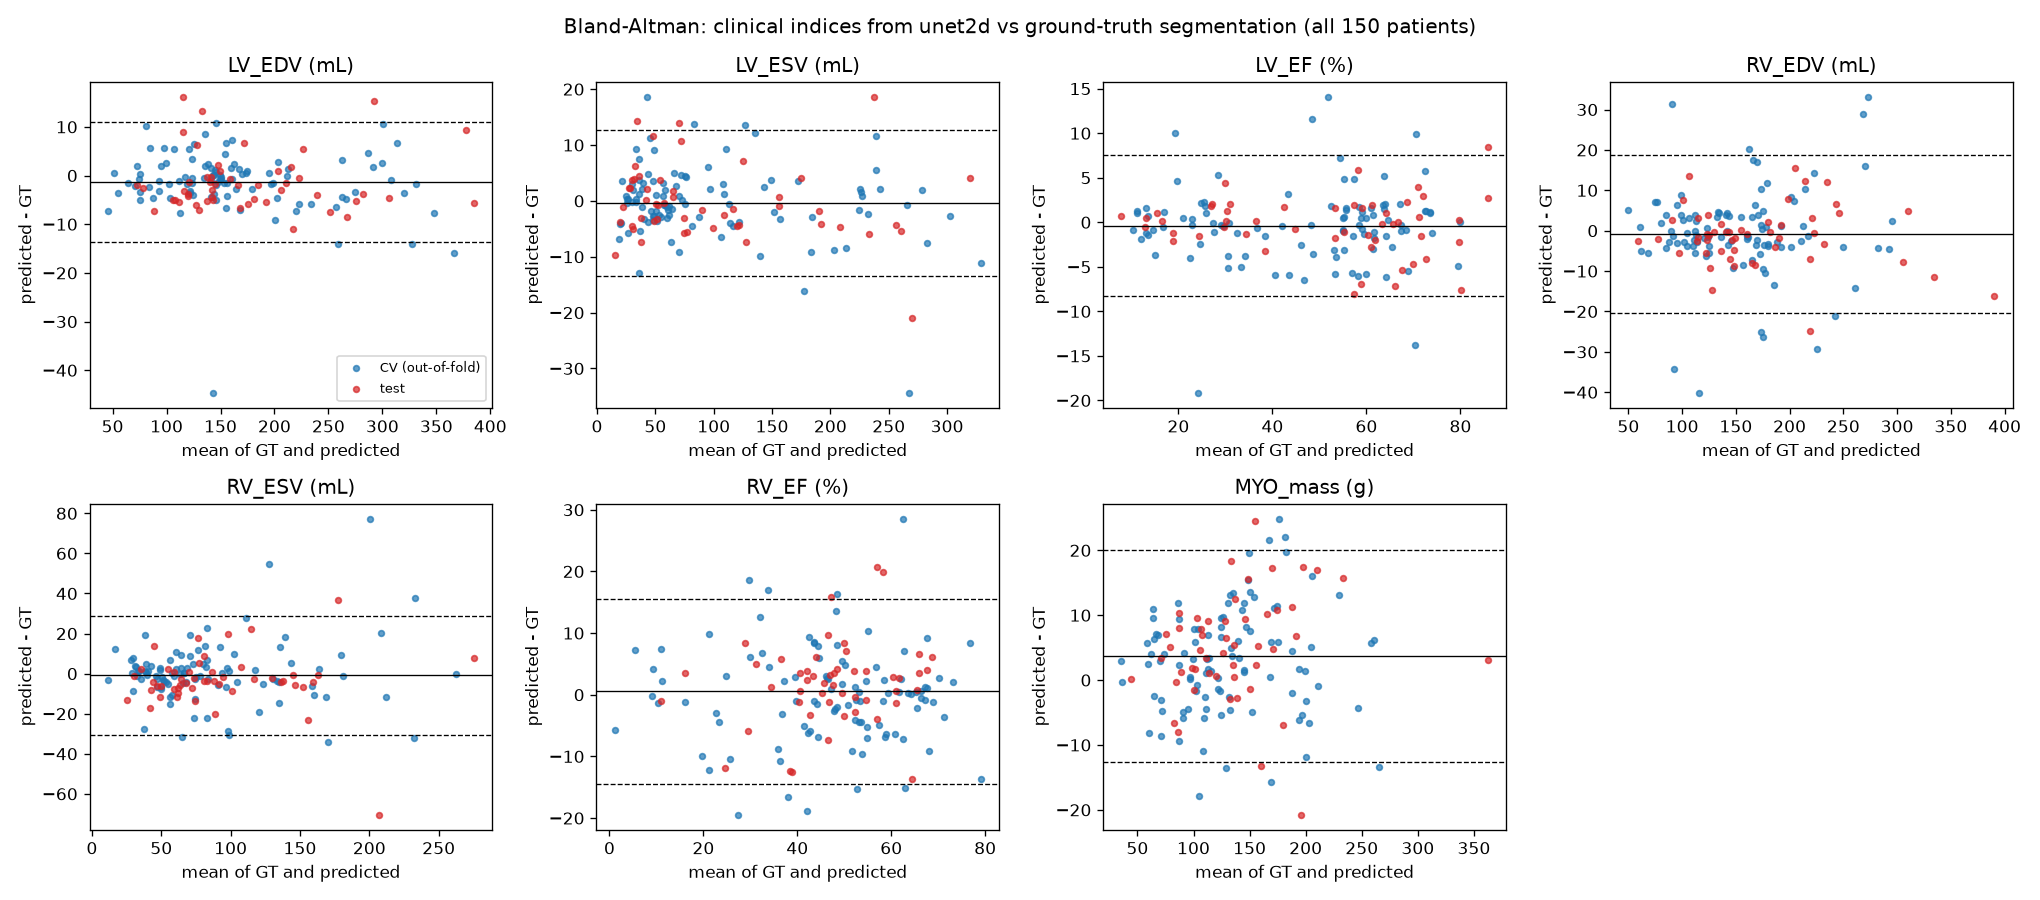

In [13]:
ca = pd.read_csv(R / "seg" / "clinical_agreement.csv")
display(ca[ca["eval"] == "test"].pivot(index="index", columns="cfg", values="pearson_r"))
display(ca[(ca["eval"] == "test") & (ca.cfg == "unet2d")])
fig("seg/fig_dice_box.png"); fig("seg/fig_bland_altman.png")

## 6. Diagnosis: two-stage pipelines vs end-to-end CNN (H2, H3)

**Two-stage.** From any segmentation (expert, U-Net, classical) we compute cardiac features: ED/ES volumes of LV and
RV, ejection fractions, myocardial mass, values indexed by body-surface area, RV/LV ratios and wall thickness
(`acdc/features.py`). Classifiers: multinomial logistic regression (standardised features, C tuned) and random forest
(max_features and min_samples_leaf tuned). Scenarios `train source -> test source`: `gt->gt` is the oracle (perfect
segmentation), `unet2d->unet2d` is the fully automatic pipeline (features of training patients come from
out-of-fold U-Net masks, so the classifier is trained on realistic errors).

**Classical image baseline (level 1, no segmentation).** Down-sampled central crops of the mid-ventricular ED, ES and
|ED-ES| slices, PCA, then the same classifiers.

**End-to-end CNN (level 2).** ImageNet-pretrained ResNet-18 applied to every slice as a 3-channel image
[ED, ES, ED-ES], mean + max pooling over slices, 5 classes; 5 seeds x 5 folds. Temperature scaling fitted on
out-of-fold predictions. **Hybrid**: average of the two-stage and CNN probabilities.

Evaluation: nested cross-validation (outer = frozen folds, inner = 5-fold grid search) on the training patients, and
the test set once. Accuracy (95% bootstrap CI), macro-F1, NLL, Brier score, ECE; McNemar tests between pipelines.

In [14]:
show_code('acdc/features.py', 'acdc/classify.py', 'acdc/train_cls.py', 'acdc/run_cls_all.sh', 'acdc/evaluate_cls.py')

**`acdc/features.py`**

"""Interpretable cardiac features computed from a segmentation (ground truth or predicted), used for diagnosis.

These are the quantities a cardiologist reads from a cine-MRI report (they are the basis of the ACDC group definitions):
  volumes      LV / RV end-diastolic and end-systolic volume (mL), also indexed by body-surface area (mL/m^2)
  function     LV / RV ejection fraction (%)
  myocardium   mass at ED (g, indexed), volume at ES, mass / LV EDV ratio
  ratios       RV / LV volume at ED and ES
  wall         myocardial thickness (mm) at ED and ES: max, mean, and the spread (std / mean) around the ring, which is
               high when one wall segment is thin (infarct scar) or thick (asymmetric hypertrophy).
"""
import numpy as np
import pandas as pd
from scipy import ndimage

from acdc.common import RESULTS, WORK, body_surface_area, clinical_indices, load_phase, volume_ml


def wall_thickness(seg_slice: np.ndarray, spacing_xy) -> np.ndarray:
    """Thickness samples (mm) of the myocardial ring in one slice: for each epicardial-border pixel, the distance to the
    LV cavity. Empty if the slice has no closed LV + myocardium."""
    myo, lv = seg_slice == 2, seg_slice == 3
    if myo.sum() < 10 or lv.sum() < 5:
        return np.zeros(0)
    dist_to_lv = ndimage.distance_transform_edt(~lv, sampling=spacing_xy)
    wall = myo | lv
    epi_border = myo & ~ndimage.binary_erosion(wall)  # outer contour of the myocardium
    return dist_to_lv[epi_border]


def thickness_stats(seg: np.ndarray, spacing_xyz):
    per_slice = [wall_thickness(s, spacing_xyz[:2]) for s in seg]
    per_slice = [t for t in per_slice if len(t) > 0]
    if not per_slice:
        return {"max": 0.0, "mean": 0.0, "cv": 0.0}
    allt = np.concatenate(per_slice)
    cv = np.mean([t.std() / (t.mean() + 1e-6) for t in per_slice])
    # robust maximum: 95th percentile within each slice, max over slices (single-pixel spikes ignored)
    return {"max": float(max(np.percentile(t, 95) for t in per_slice)), "mean": float(allt.mean()), "cv": float(cv)}


def patient_features(seg_ed, seg_es, spacing_xyz, height, weight) -> dict:
    ci = clinical_indices(seg_ed, seg_es, spacing_xyz)
    bsa = body_surface_area(height, weight)
    myo_es = volume_ml(seg_es == 2, spacing_xyz)
    f = dict(ci)
    f.update({
        "LV_EDVi": ci["LV_EDV"] / bsa, "LV_ESVi": ci["LV_ESV"] / bsa, "RV_EDVi": ci["RV_EDV"] / bsa,
        "RV_ESVi": ci["RV_ESV"] / bsa, "MYO_massi": ci["MYO_mass"] / bsa, "MYO_vol_ES": myo_es,
        "RV_LV_ED": ci["RV_EDV"] / max(ci["LV_EDV"], 1e-3), "RV_LV_ES": ci["RV_ESV"] / max(ci["LV_ESV"], 1e-3),
        "MYO_LV_ED": ci["MYO_mass"] / max(ci["LV_EDV"], 1e-3),
    })
    for ph, seg in (("ED", seg_ed), ("ES", seg_es)):
        for k, v in thickness_stats(seg, spacing_xyz).items():
            f[f"thick_{k}_{ph}"] = v
    # an empty structure gives EF = nan; replace with 0 so classifiers can still run (rare, only on failed predictions)
    return {k: (0.0 if not np.isfinite(v) else float(v)) for k, v in f.items()}


FEATURES = None  # filled on first call (column order)


def feature_table(source: str) -> pd.DataFrame:
    """Features for all 150 patients from source 'gt' (ground-truth masks) or a prediction folder name in WORK/preds."""
    global FEATURES
    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    cache = WORK / "features" / f"{source}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    rows = []
    for r in meta.itertuples():
        if source == "gt":
            _, s_ed, sp = load_phase(r.pid, "ED")
            _, s_es, _ = load_phase(r.pid, "ES")
        else:
            d = np.load(WORK / "preds" / source / f"{r.pid}.npz")
            s_ed, s_es, sp = d["seg_ED"], d["seg_ES"], (r.sx, r.sy, r.sz)
        rows.append({"pid": r.pid, "split": r.split, "fold": r.fold, "group": r.group,
                     **patient_features(s_ed, s_es, sp, r.height, r.weight)})
    df = pd.DataFrame(rows)
    cache.parent.mkdir(parents=True, e

**`acdc/classify.py`**

"""Step 4 - 5-class diagnosis (NOR / MINF / DCM / HCM / RV) from features with classical classifiers.

Feature sources
  gt            features from the ground-truth masks (oracle: what perfect segmentation would give)
  <pred cfg>    features from a predicted segmentation (e.g. unet2d, classical_lgbm). For the 100 training patients
                these are OUT-OF-FOLD predictions, so they carry realistic segmentation errors.
  image         no segmentation: down-sampled central crops of the ED / ES / |ED-ES| mid-ventricular slices -> PCA.
                The "classical image features" rung of the ladder.

Scenarios  "<train source>-><test source>":  gt->gt (oracle), gt->unet2d (train on clean features, deploy on predicted),
           unet2d->unet2d (train and deploy on predicted features: fully automatic pipeline), image->image, ...

Classifiers: multinomial logistic regression (standardised features, C tuned) and random forest (tuned).
Evaluation:
  CV   = nested cross-validation on the 100 training patients: outer loop = the frozen 5 folds, inner loop = 5-fold
         grid search on the 80 remaining patients. Gives out-of-fold probabilities for all 100.
  test = grid search (5-fold) on all 100 training patients, refit, predict the 50 test patients once.
Metrics: accuracy (95% bootstrap CI), macro-F1, negative log-likelihood, Brier score, top-label ECE (10 bins).

    python -m acdc.classify --sources unet2d classical_lgbm
"""
import argparse
import json

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from acdc.common import GROUPS, RESULTS, WORK
from acdc.features import feature_table

OUT = RESULTS / "cls"


def make_model(kind, n_features):
    if kind == "logreg":
        steps = [StandardScaler()]
        if n_features > 50:  # image features: reduce dimension first
            steps.append(PCA(n_components=20, random_state=0))
        return GridSearchCV(make_pipeline(*steps, LogisticRegression(max_iter=10000)),
                            {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]},
                            cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="neg_log_loss", n_jobs=4)
    if kind == "rf":
        return GridSearchCV(RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=4),
                            {"max_features": ["sqrt", 0.5], "min_samples_leaf": [1, 3, 5]},
                            cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="neg_log_loss", n_jobs=1)
    raise ValueError(kind)


def image_features():
    """Classical image features (no segmentation): 3 central slices of ED, ES and |ED-ES|, 128x128 px (160 mm) centre
    crop, block-averaged to 16x16 -> 3 x 3 x 256 = 2,304 values per patient (PCA inside the classifier pipeline)."""
    cache = WORK / "features" / "image.csv"
    if cache.exists():
        return pd.read_csv(cache)
    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    rows = []
    for r in meta.itertuples():
        d = np.load(WORK / "cache" / f"{r.pid}.npz")
        ed, es = d["img_ED"].astype(np.float32), d["img_ES"].astype(np.float32)
        Z, H, W = ed.shape
        zc, yc, xc = Z // 2, H // 2, W // 2
        vec = []
        for im in (ed, es, np.abs(ed - es)):
            for z in (max(zc - 1, 0), zc, min(zc + 1, Z - 1)):
                crop = im[z, yc - 64:yc + 64, xc - 64:xc + 64]
                vec.append(crop.reshape(16, 8, 16, 8).mean((1, 3)).ravel())
        v = np.concatenate(vec)
        rows.append({"pid": r.pid, "split": r.split, "fold": r.fold, "group": r.group, **{f"f{i}": x for i, x in enumerate(v)}})
    df = pd.DataFram

**`acdc/train_cls.py`**

"""Step 5 - end-to-end CNN diagnosis (no segmentation), one fold + seed per call.

    python -m acdc.train_cls --fold 0 --seed 0

Input per patient: every short-axis slice as a 3-channel image [ED, ES, ED-ES] (same slice position at the two phases,
so the difference channel shows how much the wall moves), 1.25 mm pixels, 256x256 centre crop (320 mm, contains the
heart in every ACDC case). Model: ImageNet ResNet-18 applied to each slice -> 512-d vector per slice -> mean and max over
slices -> linear layer -> 5 classes. Augmentation (same transform for all slices of a patient): rotation, scaling,
mirroring, brightness/contrast/gamma, noise. AdamW + cosine schedule, fixed number of epochs (no early stopping on the
validation fold, which stays an honest out-of-fold estimate). Saves the model and probabilities for the validation fold
(out-of-fold) and the 50 test patients.
"""
import argparse
import json
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from acdc.augment import to_canvas
from acdc.common import GROUPS, RESULTS, WORK, set_seed

CROP = 256


def load_stack(pid):
    """(Z, 3, 256, 256) float16 tensor [ED, ES, ED-ES] per slice."""
    d = np.load(WORK / "cache" / f"{pid}.npz")
    ed, es = torch.from_numpy(d["img_ED"].astype(np.float32)), torch.from_numpy(d["img_ES"].astype(np.float32))
    x = torch.stack([ed, es, ed - es], 1)
    lo = torch.tensor([float(ed.min()), float(es.min()), 0.0]).view(1, 3, 1, 1)
    canvas = to_canvas(x - lo, 0.0, CROP) + lo  # pad with each channel's minimum (0 for the difference)
    return canvas.half()


class SliceNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        self.encoder = nn.Sequential(*list(r.children())[:-2])  # up to layer4 (B,512,8,8)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(1024, len(GROUPS)))

    def slice_features(self, x):
        return F.adaptive_avg_pool2d(self.encoder(x), 1).flatten(1)

    def forward(self, stacks):
        """stacks: list of (Z_i,3,H,W) tensors (one per patient) -> (B,5) logits."""
        z = torch.cat(stacks)
        f = self.slice_features(z)
        out, i = [], 0
        for s in stacks:
            fi = f[i:i + len(s)]
            out.append(torch.cat([fi.mean(0), fi.max(0).values]))
            i += len(s)
        return self.head(torch.stack(out))


def augment(x):
    """Same random geometric transform for all slices of one patient, then intensity changes. x: (Z,3,H,W) on GPU."""
    dev = x.device
    ang = (torch.rand(1).item() * 2 - 1) * math.pi
    sc = 0.8 + 0.4 * torch.rand(1).item()
    c, s = math.cos(ang) / sc, math.sin(ang) / sc
    fx, fy = (1 if torch.rand(1) < 0.5 else -1), (1 if torch.rand(1) < 0.5 else -1)
    tx, ty = (torch.rand(2) * 0.1 - 0.05).tolist()
    theta = torch.tensor([[c * fx, -s * fy, tx], [s * fx, c * fy, ty]], device=dev, dtype=torch.float32)
    grid = F.affine_grid(theta.expand(len(x), 2, 3), x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="border", align_corners=False)
    x = x * (0.8 + 0.4 * torch.rand(1, device=dev)) + 0.2 * (torch.rand(1, device=dev) - 0.5)
    if torch.rand(1) < 0.2:
        x = x + torch.randn_like(x) * 0.1 * torch.rand(1, device=dev)
    return x


@torch.no_grad()
def predict(model, stacks, bs=8):
    model.eval()
    out = []
    for i in range(0, len(stacks), bs):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out.append(torch.softmax(model([s.cuda().float() for s in stacks[i:i + bs]]).float(), 1).cpu())
    return torch.cat(out).numpy()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--fold", type=int, required=True)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--epochs", type=int, default=120)
    ap.add_argument("

**`acdc/run_cls_all.sh`**

#!/usr/bin/env bash
# All end-to-end CNN classifier runs: 5 seeds x 5 folds (skips runs that already finished).
cd "$(dirname "$0")/.."
UV=${UV:-$(command -v uv || echo ~/.local/bin/uv)}  # uv on PATH, else the default install location
for s in 0 1 2 3 4; do for f in 0 1 2 3 4; do
  [ -f results/cls/cnn_runs/resnet18_s${s}_f${f}.csv ] && continue
  $UV run python -m acdc.train_cls --fold $f --seed $s 2>&1 | grep -v Warn | tail -n 2
done; done

**`acdc/evaluate_cls.py`**

"""Step 8 - diagnosis evaluation: compare all pipelines (results/cls/).

    python -m acdc.evaluate_cls --seg_cfgs unet2d unet25d classical_lgbm

Pipelines compared (test = 50 held-out patients, CV = out-of-fold on the 100 training patients):
  image features -> LR             classical, no segmentation
  CNN end-to-end (ResNet-18)       per seed (5 seeds, test = 5-fold ensemble), mean +- sd over seeds, and the
                                   ensemble of all 25 models; + temperature scaling fitted on the out-of-fold predictions
  GT masks -> features -> LR / RF  oracle
  <seg> masks -> features -> LR/RF automatic two-stage pipeline (seg = U-Net or classical segmentation)
Outputs: pipelines.csv (main table), cnn_seeds.csv, mcnemar.csv, coverage.csv, fig_coverage.png, fig_confusion.png
"""
import argparse
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, stats
from sklearn.metrics import confusion_matrix

from acdc.classify import metrics
from acdc.common import GROUPS, RESULTS

OUT = RESULTS / "cls"
ENC = {g: i for i, g in enumerate(GROUPS)}
PCOLS = [f"p_{g}" for g in GROUPS]


def fit_temperature(prob, y):
    """Single temperature T minimising NLL of softmax(log p / T)."""
    logp = np.log(np.clip(prob, 1e-7, 1))

    def nll(t):
        z = logp / t
        z = z - z.max(1, keepdims=True)
        q = np.exp(z) / np.exp(z).sum(1, keepdims=True)
        return -np.log(q[np.arange(len(y)), y] + 1e-12).mean()
    return optimize.minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x


def apply_temperature(prob, t):
    z = np.log(np.clip(prob, 1e-7, 1)) / t
    z = z - z.max(1, keepdims=True)
    return np.exp(z) / np.exp(z).sum(1, keepdims=True)


def cnn_results(tag="resnet18"):
    """Returns {name: (cv_df, test_df)} prob tables for each seed and for the all-seed ensemble, plus a per-seed table."""
    runs = [pd.read_csv(p) for p in sorted((OUT / "cnn_runs").glob(f"{tag}_s*_f*.csv"))]
    if not runs:
        return {}, pd.DataFrame()
    df = pd.concat(runs)
    out, rows = {}, []
    for seed, d in df.groupby("seed"):
        if d.fold.nunique() < 5:
            continue
        cv = d[d["eval"] == "cv"].sort_values("pid")
        te = d[d["eval"] == "test"].groupby(["pid", "group"])[PCOLS].mean().reset_index()  # 5-fold ensemble
        out[f"cnn_s{seed}"] = (cv, te)
        y_cv, y_te = cv.group.map(ENC).values, te.group.map(ENC).values
        t = fit_temperature(cv[PCOLS].values, y_cv)
        r = {"seed": seed, "T": t}
        for ev, dd, y in (("cv", cv, y_cv), ("test", te, y_te)):
            r.update({f"{ev}_{k}": v for k, v in metrics(dd[PCOLS].values, y).items() if k in ("acc", "macro_f1", "nll", "brier", "ece")})
        m_ts = metrics(apply_temperature(te[PCOLS].values, t), y_te)
        r.update({f"test_ts_{k}": m_ts[k] for k in ("acc", "nll", "brier", "ece")})
        rows.append(r)
    seeds = [s for s in df.seed.unique() if f"cnn_s{s}" in out]
    if seeds:
        dd = df[df.seed.isin(seeds)]
        cv = dd[dd["eval"] == "cv"].groupby(["pid", "group"])[PCOLS].mean().reset_index()
        te = dd[dd["eval"] == "test"].groupby(["pid", "group"])[PCOLS].mean().reset_index()
        out["cnn_ensemble"] = (cv, te)
    return out, pd.DataFrame(rows)


def feature_results(seg_cfgs):
    out = {}
    scen = [("image", "image")] + [("gt", "gt")] + [(a, b) for s in seg_cfgs for a, b in (("gt", s), (s, s))]
    for tr, te in scen:
        for kind in ("logreg", "rf"):
            p = OUT / "probs" / f"{tr}__{te}__{kind}.csv"
            if p.exists():
                d = pd.read_csv(p)
                out[f"{tr}->{te} {kind}"] = (d[d["eval"] == "cv"], d[d["eval"] == "test"])
    return out


def mcnemar(a, b, y):
    """Exact McNemar test on paired correct/incorrect predictions."""
    ca, cb = a.argmax(1) == y, b.argmax(1) == y
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = stats.bino

In [15]:
if RUN["train_cnn"]:
    run("bash acdc/run_cls_all.sh")
if RUN["classify"]:
    run("python -m acdc.classify --sources unet2d unet25d classical_lgbm unet2d_noaug unet2d_ce")

In [16]:
# Live check (seconds): refit the main automatic pipeline (U-Net features -> logistic regression) on the 100 training
# patients and predict the 50 test patients; should match the stored result. Needs the feature cache (ACDC_WORK).
from acdc.classify import make_model, table
from acdc.common import GROUPS
try:
    tab = table("unet2d"); feats = [c for c in tab.columns if c not in ("pid", "split", "fold", "group")]
    tr, te = tab[tab.split == "train"], tab[tab.split == "test"]
    m = make_model("logreg", len(feats)).fit(tr[feats].values, tr.group.map(GROUPS.index).values)
    acc = (m.predict(te[feats].values) == te.group.map(GROUPS.index).values).mean()
    print(f"re-fitted now: test accuracy {acc:.2f}, best C = {m.best_params_}")
except FileNotFoundError as e:
    print("feature cache not available here:", e)

re-fitted now: test accuracy 0.94, best C = {'logisticregression__C': 3}


**Diagnosis, test**

,acc,acc_lo,acc_hi,macro_f1,nll,brier,ece
pipeline,,,,,,,
image->image logreg,0.480,0.34,0.62,0.462,1.232,0.627,0.135
image->image rf,0.520,0.38,0.66,0.523,1.267,0.645,0.157
gt->gt logreg,0.960,0.90,1.00,0.960,0.194,0.071,0.065
gt->gt rf,0.900,0.80,0.98,0.899,0.358,0.179,0.107
gt->unet2d logreg,0.920,0.84,0.98,0.920,0.320,0.131,0.031
gt->unet2d rf,0.940,0.86,1.00,0.940,0.365,0.169,0.115
unet2d->unet2d logreg,0.940,0.86,1.00,0.939,0.238,0.103,0.048
unet2d->unet2d rf,0.880,0.78,0.96,0.880,0.331,0.170,0.099
gt->unet25d logreg,0.920,0.84,0.98,0.920,0.349,0.139,0.044


**Diagnosis, cv**

,acc,acc_lo,acc_hi,macro_f1,nll,brier,ece
pipeline,,,,,,,
image->image logreg,0.430,0.34,0.53,0.429,1.591,0.776,0.145
image->image rf,0.410,0.31,0.51,0.386,1.426,0.719,0.077
gt->gt logreg,0.970,0.93,1.00,0.970,0.076,0.045,0.026
gt->gt rf,0.940,0.89,0.98,0.940,0.285,0.138,0.110
gt->unet2d logreg,0.910,0.85,0.96,0.911,0.310,0.162,0.076
gt->unet2d rf,0.890,0.83,0.95,0.890,0.340,0.172,0.085
unet2d->unet2d logreg,0.920,0.86,0.97,0.920,0.177,0.099,0.031
unet2d->unet2d rf,0.910,0.85,0.96,0.910,0.350,0.177,0.128
gt->unet25d logreg,0.920,0.86,0.97,0.920,0.291,0.133,0.061


**End-to-end CNN per seed, with temperature scaling**

,seed,T,cv_acc,cv_macro_f1,cv_nll,cv_brier,cv_ece,test_acc,test_macro_f1,test_nll,test_brier,test_ece,test_ts_acc,test_ts_nll,test_ts_brier,test_ts_ece
0,0,2.285,0.74,0.737,1.013,0.425,0.191,0.84,0.840,0.443,0.210,0.113,0.84,0.549,0.267,0.175
1,1,2.428,0.72,0.717,1.076,0.423,0.184,0.86,0.861,0.438,0.205,0.066,0.86,0.600,0.295,0.254
2,2,1.989,0.74,0.735,0.837,0.383,0.165,0.84,0.841,0.405,0.223,0.076,0.84,0.511,0.257,0.145
3,3,2.050,0.79,0.788,0.855,0.358,0.139,0.86,0.857,0.463,0.229,0.075,0.86,0.543,0.271,0.182
4,4,2.184,0.73,0.730,0.921,0.422,0.179,0.84,0.841,0.377,0.198,0.059,0.84,0.518,0.256,0.159


**McNemar tests vs the main automatic pipeline**

,ref,other,eval,ref_right_other_wrong,ref_wrong_other_right,mcnemar_p
0,unet2d->unet2d logreg,image->image logreg,cv,51,2,3.180e-13
1,unet2d->unet2d logreg,image->image logreg,test,23,0,2.384e-07
2,unet2d->unet2d logreg,image->image rf,cv,52,1,1.199e-14
3,unet2d->unet2d logreg,image->image rf,test,21,0,9.537e-07
4,unet2d->unet2d logreg,gt->gt logreg,cv,1,6,1.250e-01
...,...,...,...,...,...,...
57,unet2d->unet2d logreg,cnn_ensemble,test,6,2,2.891e-01
58,unet2d->unet2d logreg,cnn_ensemble+TS,cv,19,2,2.213e-04
59,unet2d->unet2d logreg,cnn_ensemble+TS,test,6,2,2.891e-01
60,unet2d->unet2d logreg,hybrid (unet2d->unet2d logreg + cnn_ensemble),cv,1,2,1.000e+00


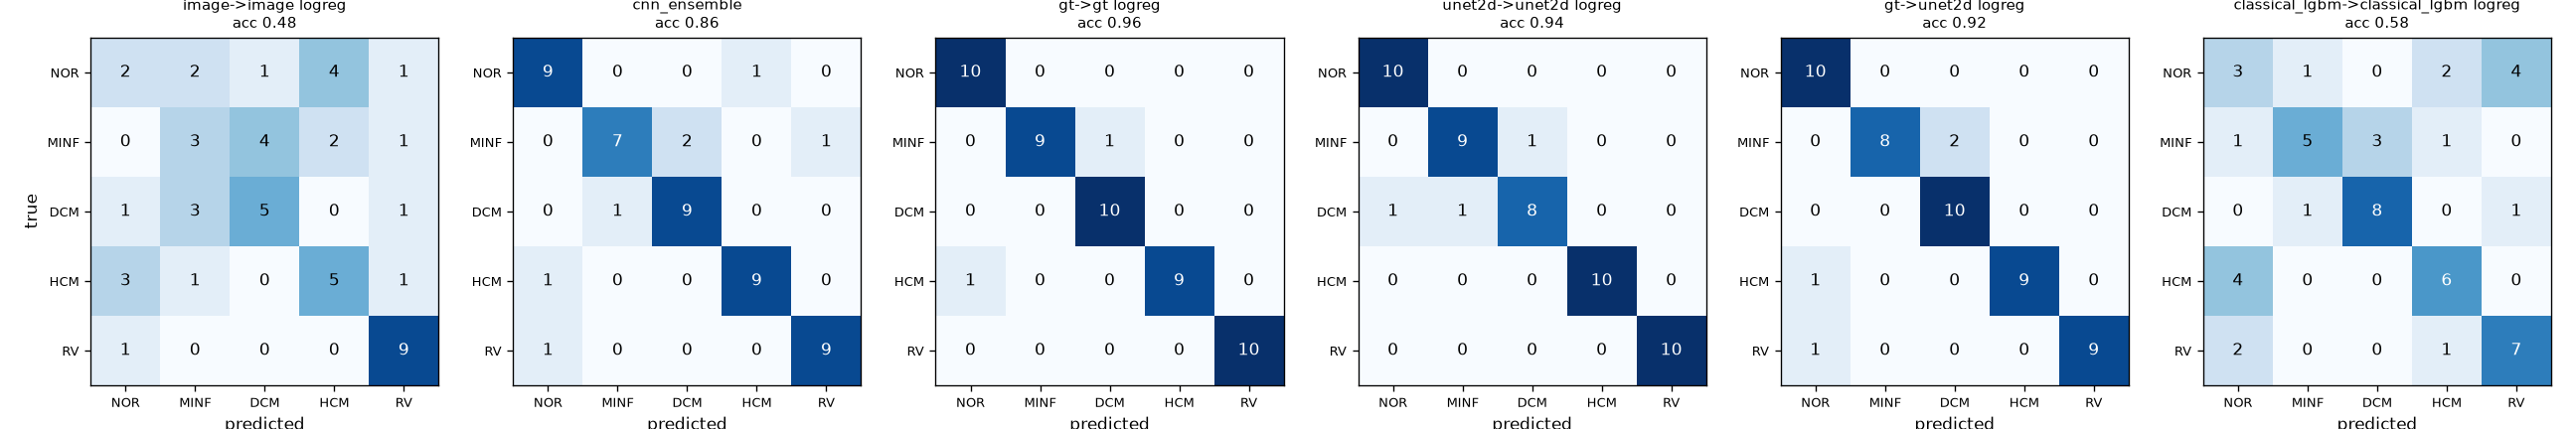

**Most important features (random forest on U-Net features)**

,importance
RV_LV_ED,0.144
LV_EF,0.129
LV_ESVi,0.080
RV_LV_ES,0.074
thick_mean_ES,0.072
LV_ESV,0.065
thick_mean_ED,0.050
thick_max_ES,0.048
thick_max_ED,0.046
LV_EDV,0.043


In [17]:
pl = pd.read_csv(R / "cls" / "pipelines.csv")
cols = ["acc", "acc_lo", "acc_hi", "macro_f1", "nll", "brier", "ece"]
for ev in ("test", "cv"):
    display(Markdown(f"**Diagnosis, {ev}**")); display(pl[pl["eval"] == ev].set_index("pipeline")[cols])
display(Markdown("**End-to-end CNN per seed, with temperature scaling**")); display(pd.read_csv(R / "cls" / "cnn_seeds.csv"))
mc = pd.read_csv(R / "cls" / "mcnemar.csv"); display(Markdown("**McNemar tests vs the main automatic pipeline**")); display(mc)
fig("cls/fig_confusion.png")
imp = pd.read_csv(R / "cls" / "rf_importance_unet2d.csv", index_col=0)
display(Markdown("**Most important features (random forest on U-Net features)**")); display(imp.head(10))

## 7. Failure analysis and mitigations (H4)

We look for where the system stops working, and test a mitigation for each important failure mode:

| failure mode | analysis | mitigation tested |
|---|---|---|
| hard anatomy (apex / base slices, RV) | Dice by slice position and structure | 2.5D input (neighbouring slices) |
| some patient groups are harder | Dice and errors by diagnostic group | (reported) |
| a segmentation fails silently | uncertainty (entropy, fold disagreement) vs Dice; AUROC for failure (any Dice < 0.80) | refer the most uncertain cases (coverage) |
| diagnosis errors | confusion matrices, coverage-accuracy curves | refer least-confident cases; hybrid model |
| image-quality degradation | 6 degradations x 4 severities on the test images, full pipeline re-run | data augmentation (vs no-augmentation model) |
| does the CNN look at the right place | Grad-CAM vs expert heart masks (energy in heart, enrichment, pointing game) | (interpretability check) |

In [18]:
show_code('acdc/robustness.py', 'acdc/gradcam.py')

**`acdc/robustness.py`**

"""Step 7 - robustness to image-quality degradations (failure analysis), on the 50 test patients.

Each degradation is applied to the RAW image on its original grid (before normalisation / resampling), at increasing
severity, then the full pipeline runs unchanged: normalise -> resample -> segmentation (5-fold ensemble, no TTA) ->
clinical features -> diagnosis (logistic regression trained on the out-of-fold predicted features of the 100 training
patients of the same segmentation model, i.e. the automatic pipeline "<cfg>-><cfg>").

  noise      Rician noise (Gaussian on real + imaginary channel), sigma = level x 99th intensity percentile
  blur       Gaussian in-plane blur, sigma in mm
  lowres     in-plane down-sampling by a factor, then bilinear up-sampling back
  bias       smooth multiplicative intensity field (coil inhomogeneity), exp(level * random smooth field in [-1, 1])
  ghosting   motion: 30% of phase-encoding lines (k-space rows) get a random in-plane shift of up to `level` pixels
  gamma      contrast change x -> x^level on the [0, 1]-rescaled image

    python -m acdc.robustness --cfgs unet2d unet2d_noaug unet25d
Writes results/robustness/robustness_seg.csv, robustness_cls.csv, fig_robustness.png
"""
import argparse

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage

from acdc.classify import make_model
from acdc.common import CLASSES, GROUPS, RESULTS, WORK, dice, keep_largest_component, load_phase, normalize, \
    probs_to_original, resample_image
from acdc.features import feature_table, patient_features
from acdc.infer import load_model, predict_volume

OUT = RESULTS / "robustness"
LEVELS = {"noise": [0.02, 0.05, 0.1, 0.15], "blur": [1.0, 2.0, 3.0, 4.0], "lowres": [1.5, 2.0, 3.0, 4.0],
          "bias": [0.2, 0.4, 0.6, 0.8], "ghosting": [2, 4, 8, 12], "gamma": [0.5, 0.7, 1.5, 2.0]}


def degrade(img, spacing, kind, level, rng):
    """img: (Z,X,Y) float32 raw intensities on the original grid."""
    if kind == "noise":
        s = level * np.percentile(img, 99)
        return np.sqrt((img + rng.normal(0, s, img.shape)) ** 2 + rng.normal(0, s, img.shape) ** 2).astype(np.float32)
    if kind == "blur":
        return ndimage.gaussian_filter(img, sigma=(0, level / spacing[0], level / spacing[1])).astype(np.float32)
    if kind == "lowres":
        t = torch.from_numpy(img)[:, None]
        small = torch.nn.functional.interpolate(t, scale_factor=1 / level, mode="area")
        return torch.nn.functional.interpolate(small, size=img.shape[1:], mode="bilinear", align_corners=False)[:, 0].numpy()
    if kind == "bias":
        Z, X, Y = img.shape
        coarse = rng.uniform(-1, 1, (4, 4))  # smooth random field from a 4x4 grid of control values
        field = ndimage.zoom(coarse, (X / 4, Y / 4), order=3)[:X, :Y]
        field = field / (np.abs(field).max() + 1e-8)
        return (img * np.exp(level * field)[None]).astype(np.float32)
    if kind == "ghosting":
        out = np.empty_like(img)
        for z in range(img.shape[0]):
            k = np.fft.fftshift(np.fft.fft2(img[z]))
            rows = rng.random(k.shape[0]) < 0.3  # corrupted phase-encode lines
            shifts = rng.uniform(-level, level, rows.sum())
            ky = np.fft.fftshift(np.fft.fftfreq(k.shape[1]))
            k[rows] *= np.exp(-2j * np.pi * shifts[:, None] * ky[None, :])
            out[z] = np.abs(np.fft.ifft2(np.fft.ifftshift(k)))
        return out.astype(np.float32)
    if kind == "gamma":
        lo, hi = img.min(), img.max()
        return (((img - lo) / (hi - lo + 1e-8)) ** level * (hi - lo) + lo).astype(np.float32)
    raise ValueError(kind)


def segment(models, in_ch, img, spacing):
    x = torch.from_numpy(resample_image(normalize(img), spacing[:2]))
    p = predict_volume(models, x, in_ch, tta=False)
    return keep_largest_component(probs_to_original(p, img.shape[1:]).argmax(1).numpy().astype(np.uint8))


def main():
    ap =

**`acdc/gradcam.py`**

"""Step 9 - Grad-CAM for the end-to-end CNN: does it look at the heart?

For each test patient and each of the 5 fold models of one seed, Grad-CAM (Selvaraju et al., 2017) is computed for the
predicted class on the last ResNet block, for every slice (the model sees all slices at once; the gradient of the
patient-level logit gives one map per slice). Maps are averaged over the 5 models and compared with the ground-truth
heart (RV + myocardium + LV, ED or ES, dilated by 10 px = 12.5 mm):
  energy_in_heart   fraction of the total CAM energy (all slices) that falls inside the heart region
  heart_area        fraction of the image area covered by the heart region (= expected energy fraction if the CAM
                    were spread uniformly); enrichment = energy_in_heart / heart_area
  pointing_game     whether the single highest CAM pixel lies inside the heart region
Results are split by correct vs wrong predictions. This replaces the planned "Grad-CAM vs radiologist boxes" analysis
for the new dataset.

    python -m acdc.gradcam --seed 0
Writes results/cls/gradcam.csv, gradcam_summary.json, fig_gradcam.png
"""
import argparse
import json

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import ndimage

from acdc.augment import to_canvas
from acdc.common import GROUPS, RESULTS, WORK
from acdc.train_cls import CROP, SliceNet, load_stack

OUT = RESULTS / "cls"


def gradcam(model, stack):
    """stack: (Z,3,H,W) on GPU. Returns (CAM (Z,H,W) in [0,1] scale-free, predicted class, probabilities)."""
    feats = {}
    h = model.encoder.register_forward_hook(lambda m, i, o: feats.__setitem__("a", o))
    model.eval()
    logits = model([stack])
    h.remove()
    a = feats["a"]  # (Z,512,8,8)
    c = int(logits.argmax(1))
    g = torch.autograd.grad(logits[0, c], a)[0]
    w = g.mean((2, 3), keepdim=True)  # channel weights per slice
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=stack.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return cam.detach().cpu().numpy(), c, torch.softmax(logits, 1)[0].detach().cpu().numpy()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--tag", default="resnet18")
    args = ap.parse_args()
    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    test = meta[meta.split == "test"]
    models = []
    for f in range(5):
        ck = torch.load(WORK / "runs" / f"cls_{args.tag}_s{args.seed}_f{f}" / "model.pt", map_location="cpu", weights_only=False)
        m = SliceNet(pretrained=False)
        m.load_state_dict(ck["model"])
        models.append(m.cuda().eval())
    rows, examples = [], []
    for r in test.itertuples():
        x = load_stack(r.pid).cuda().float()
        cams, probs = [], []
        for m in models:
            cam, _, p = gradcam(m, x)
            cams.append(cam / (cam.max() + 1e-8))  # each model's maps scaled to [0,1] before averaging
            probs.append(p)
        cam, prob = np.mean(cams, 0), np.mean(probs, 0)
        d = np.load(WORK / "cache" / f"{r.pid}.npz")
        heart = torch.from_numpy(((d["lab_ED"] > 0) | (d["lab_ES"] > 0)).astype(np.uint8))
        heart = to_canvas(heart, 0, CROP).numpy().astype(bool)
        heart = np.stack([ndimage.binary_dilation(s, iterations=10) if s.any() else s for s in heart])
        has = heart.any((1, 2))  # slices that contain the heart
        e_in = cam[heart].sum() / (cam.sum() + 1e-8)
        area = heart.mean()  # over all slices, like the energy fraction
        z, yy, xx = np.unravel_index(np.argmax(cam), cam.shape)
        pred = int(prob.argmax())
        rows.append({"pid": r.pid, "group": r.group, "pred": GROUPS[pred], "correct": GROUPS[pred] == r.group,
                     "energy_in_heart": float(e_in), "heart_area": float(area), "enrichment": float(e_in / area),
                     "energy

**Dice by slice position (test)**

position                   apex   base    mid
cfg            structure                     
classical_lgbm LV         0.558  0.774  0.769
               MYO        0.479  0.703  0.654
               RV         0.257  0.504  0.525
unet25d        LV         0.882  0.956  0.950
               MYO        0.846  0.912  0.919
               RV         0.795  0.878  0.933
unet2d         LV         0.867  0.957  0.951
               MYO        0.843  0.913  0.919
               RV         0.787  0.885  0.930
unet2d_ce      LV         0.858  0.957  0.952
               MYO        0.839  0.912  0.917
               RV         0.785  0.875  0.928
unet2d_noaug   LV         0.859  0.955  0.950
               MYO        0.813  0.904  0.913
               RV         0.730  0.836  0.920
unet2d_nopp    LV         0.858  0.957  0.959
               MYO        0.851  0.913  0.919
               RV         0.788  0.885  0.931
unet2d_notta   LV         0.866  0.957  0.950
               MYO        0.842  0.911  0.917
               RV         0.791  0.880  0.929

**Dice by diagnostic group (test)**

split  dice_RV  dice_MYO  dice_LV
cfg            group                                  
classical_lgbm DCM    test    0.479     0.623    0.785
               HCM    test    0.488     0.587    0.676
               MINF   test    0.525     0.649    0.821
               NOR    test    0.581     0.654    0.731
               RV     test    0.592     0.714    0.674
unet2d         DCM    test    0.944     0.902    0.973
               HCM    test    0.901     0.928    0.896
               MINF   test    0.897     0.912    0.967
               NOR    test    0.930     0.914    0.943
               RV     test    0.939     0.913    0.955
unet25d        DCM    test    0.940     0.903    0.973
               HCM    test    0.906     0.923    0.890
               MINF   test    0.893     0.911    0.966
               NOR    test    0.928     0.912    0.935
               RV     test    0.940     0.911    0.955
unet2d_noaug   DCM    test    0.933     0.892    0.971
               HCM    test    0.890     0.915    0.874
               MINF   test    0.882     0.901    0.963
               NOR    test    0.919     0.900    0.928
               RV     test    0.919     0.899    0.948
unet2d_ce      DCM    test    0.942     0.901    0.973
               HCM    test    0.894     0.926    0.890
               MINF   test    0.898     0.909    0.966
               NOR    test    0.930     0.911    0.935
               RV     test    0.936     0.910    0.954
unet2d_notta   DCM    test    0.943     0.901    0.973
               HCM    test    0.902     0.928    0.896
               MINF   test    0.900     0.911    0.967
               NOR    test    0.921     0.912    0.938
               RV     test    0.937     0.909    0.954
unet2d_nopp    DCM    test    0.944     0.904    0.973
               HCM    test    0.901     0.927    0.908
               MINF   test    0.897     0.913    0.967
               NOR    test    0.929     0.913    0.943
               RV     test    0.939     0.913    0.954

**Uncertainty as a failure detector**

,cfg,eval,score,n_volumes,n_fail,spearman_vs_dice,auroc_fail,mean_dice_all,mean_dice_drop10,fails_drop10,mean_dice_drop20,fails_drop20,mean_dice_drop30,fails_drop30
0,classical_lgbm,cv,ent_fg,200,193,-0.469,0.848,0.643,0.660,173,0.669,153,0.680,133
1,classical_lgbm,test,ent_fg,100,96,-0.606,0.708,0.639,0.664,86,0.681,77,0.701,66
2,unet2d,cv,ent_fg,200,20,-0.596,0.759,0.921,0.926,14,0.930,9,0.932,7
3,unet2d,test,ent_fg,100,9,-0.539,0.822,0.928,0.932,5,0.934,3,0.936,3
4,unet2d,test,disagree,100,9,-0.657,0.839,0.928,0.932,5,0.935,4,0.938,1
5,unet25d,cv,ent_fg,200,20,-0.574,0.762,0.920,0.926,14,0.930,7,0.932,5
6,unet25d,test,ent_fg,100,10,-0.584,0.800,0.926,0.928,7,0.932,5,0.936,3
7,unet25d,test,disagree,100,10,-0.666,0.838,0.926,0.929,7,0.933,5,0.937,2
8,unet2d_noaug,cv,ent_fg,200,29,-0.222,0.691,0.906,0.911,22,0.915,16,0.915,13
9,unet2d_noaug,test,ent_fg,100,13,-0.597,0.790,0.916,0.919,10,0.921,8,0.924,4


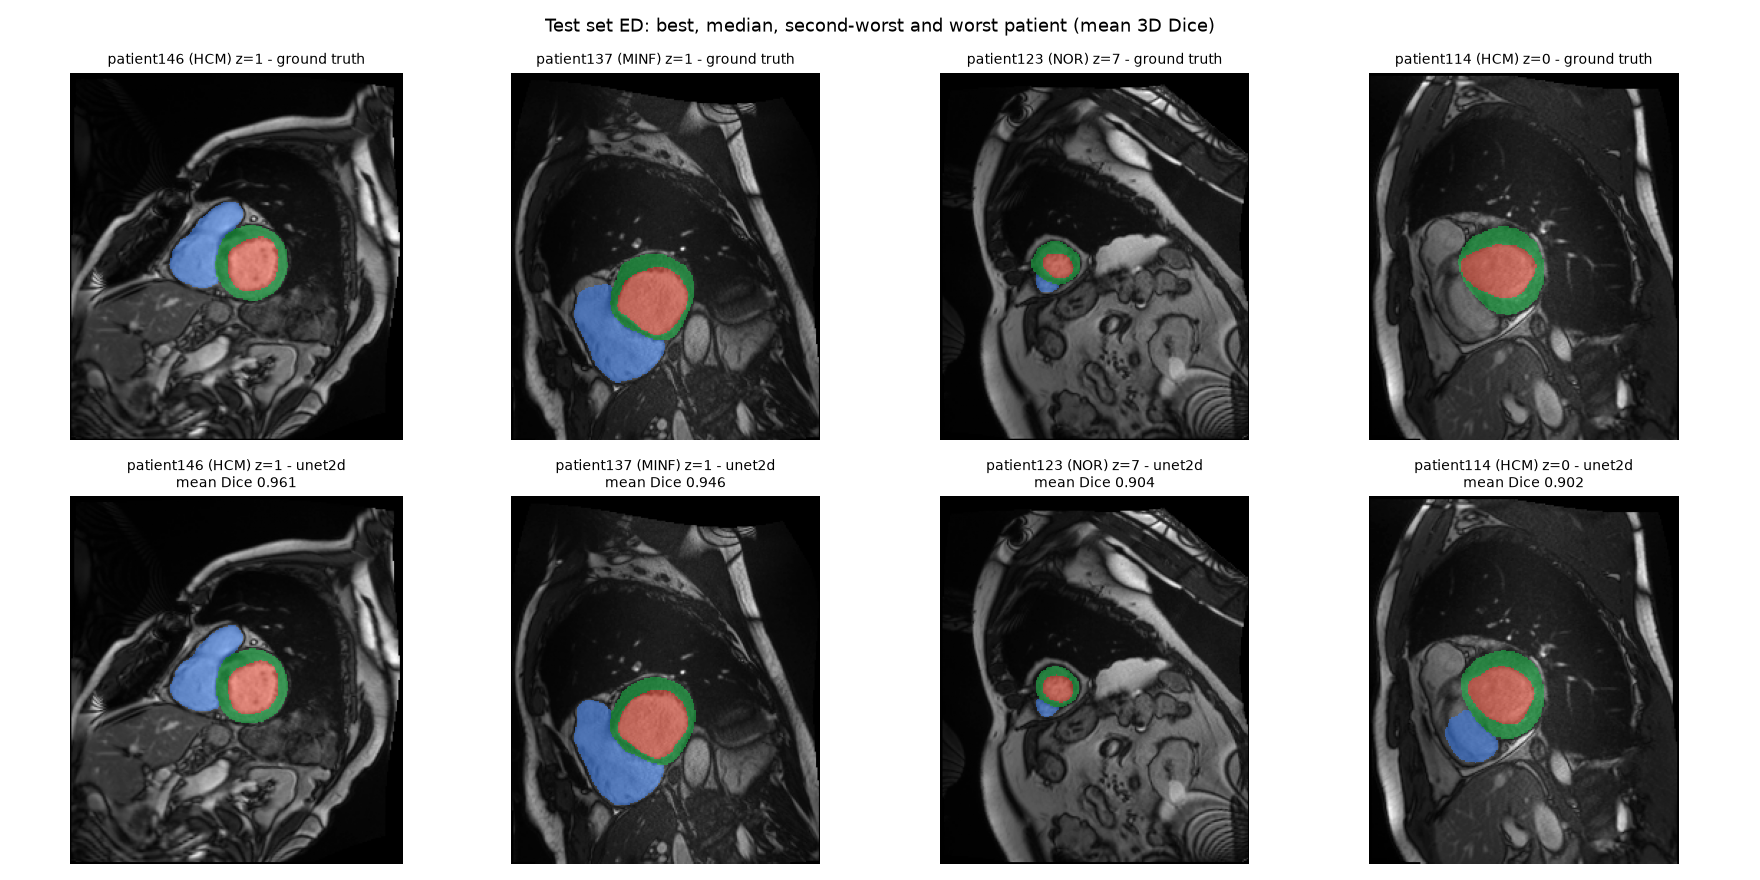

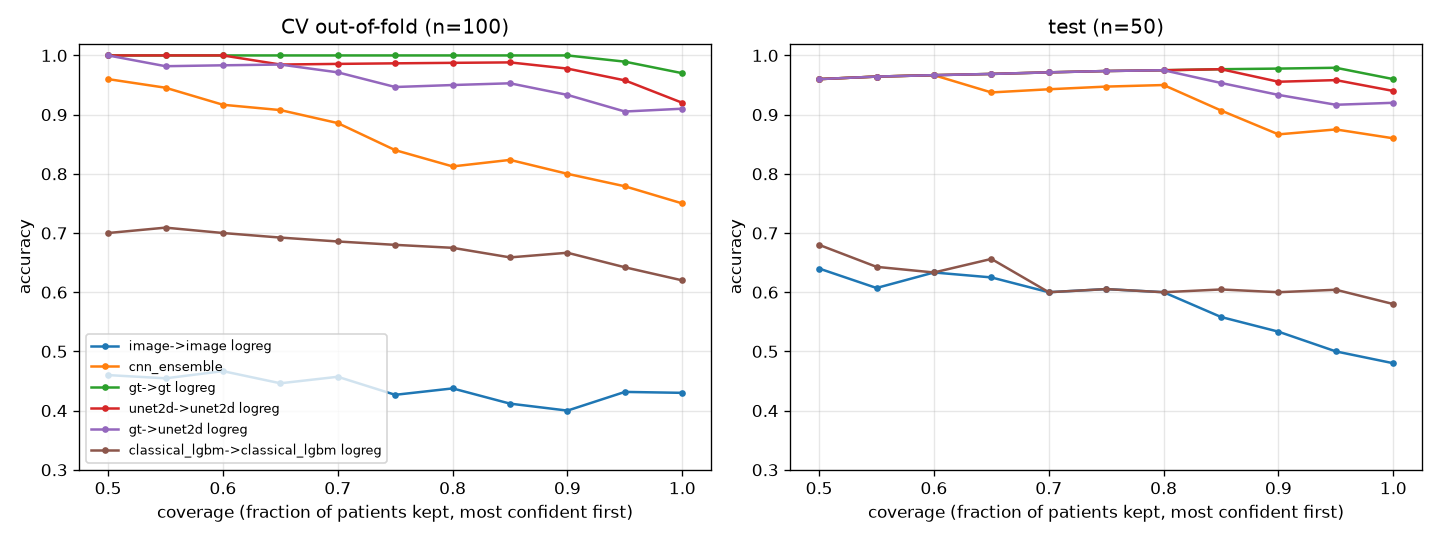

In [19]:
sp = pd.read_csv(R / "seg" / "slice_position.csv")
display(Markdown("**Dice by slice position (test)**"))
display(sp[sp["eval"] == "test"].pivot_table(index=["cfg", "structure"], columns="position", values="mean").round(3))
display(Markdown("**Dice by diagnostic group (test)**"))
display(pd.read_csv(R / "seg" / "dice_by_group.csv").query("split == 'test'").set_index(["cfg", "group"]))
display(Markdown("**Uncertainty as a failure detector**")); display(pd.read_csv(R / "seg" / "uncertainty.csv"))
fig("seg/fig_examples_best_worst.png"); fig("cls/fig_coverage.png")

diag_acc                     mean_dice                    
cfg                unet25d unet2d unet2d_noaug   unet25d unet2d unet2d_noaug
degradation level                                                           
bias        0.20      0.96   0.94         0.98     0.924  0.925        0.914
            0.40      0.96   0.94         0.94     0.923  0.924        0.914
            0.60      0.96   0.96         0.92     0.918  0.919        0.911
            0.80      0.96   0.92         0.98     0.910  0.916        0.903
blur        1.00      0.94   0.94         0.94     0.924  0.926        0.913
            2.00      0.96   0.94         0.94     0.914  0.917        0.892
            3.00      0.94   0.90         0.86     0.888  0.892        0.859
            4.00      0.84   0.82         0.78     0.853  0.850        0.818
clean       0.00      0.96   0.94         0.98     0.925  0.926        0.916
gamma       0.50      0.96   0.94         0.94     0.924  0.924        0.911
            0.70      0.96   0.94         0.92     0.925  0.926        0.915
            1.50      0.96   0.94         0.98     0.924  0.925        0.911
            2.00      0.94   0.92         0.96     0.921  0.922        0.898
ghosting    2.00      0.96   0.94         0.98     0.920  0.921        0.909
            4.00      0.98   0.96         0.94     0.908  0.911        0.894
            8.00      0.96   0.96         0.90     0.890  0.891        0.872
            12.00     0.86   0.92         0.94     0.869  0.869        0.852
lowres      1.50      0.94   0.96         0.96     0.915  0.918        0.905
            2.00      0.96   0.96         0.94     0.916  0.918        0.903
            3.00      0.96   0.92         0.92     0.898  0.899        0.876
            4.00      0.92   0.92         0.84     0.873  0.873        0.853
noise       0.02      0.96   0.96         0.96     0.923  0.924        0.914
            0.05      0.96   0.96         0.96     0.919  0.920        0.902
            0.10      0.98   0.94         0.88     0.905  0.902        0.860
            0.15      0.96   0.92         0.78     0.879  0.866        0.781

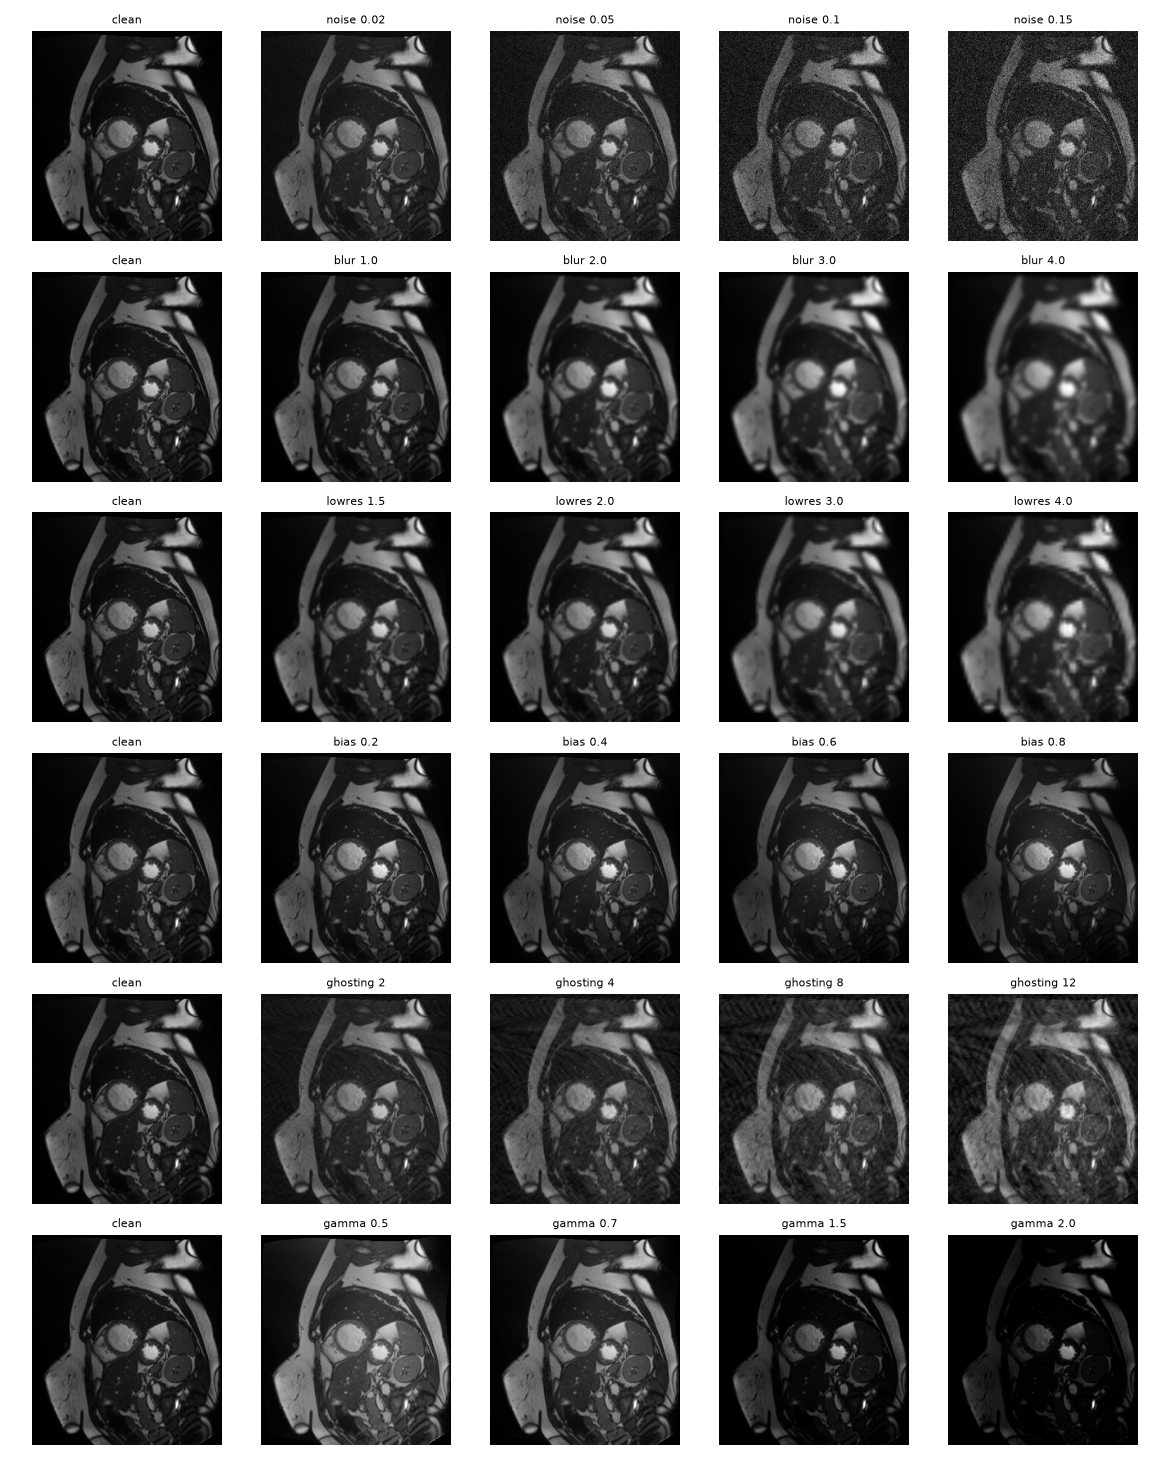

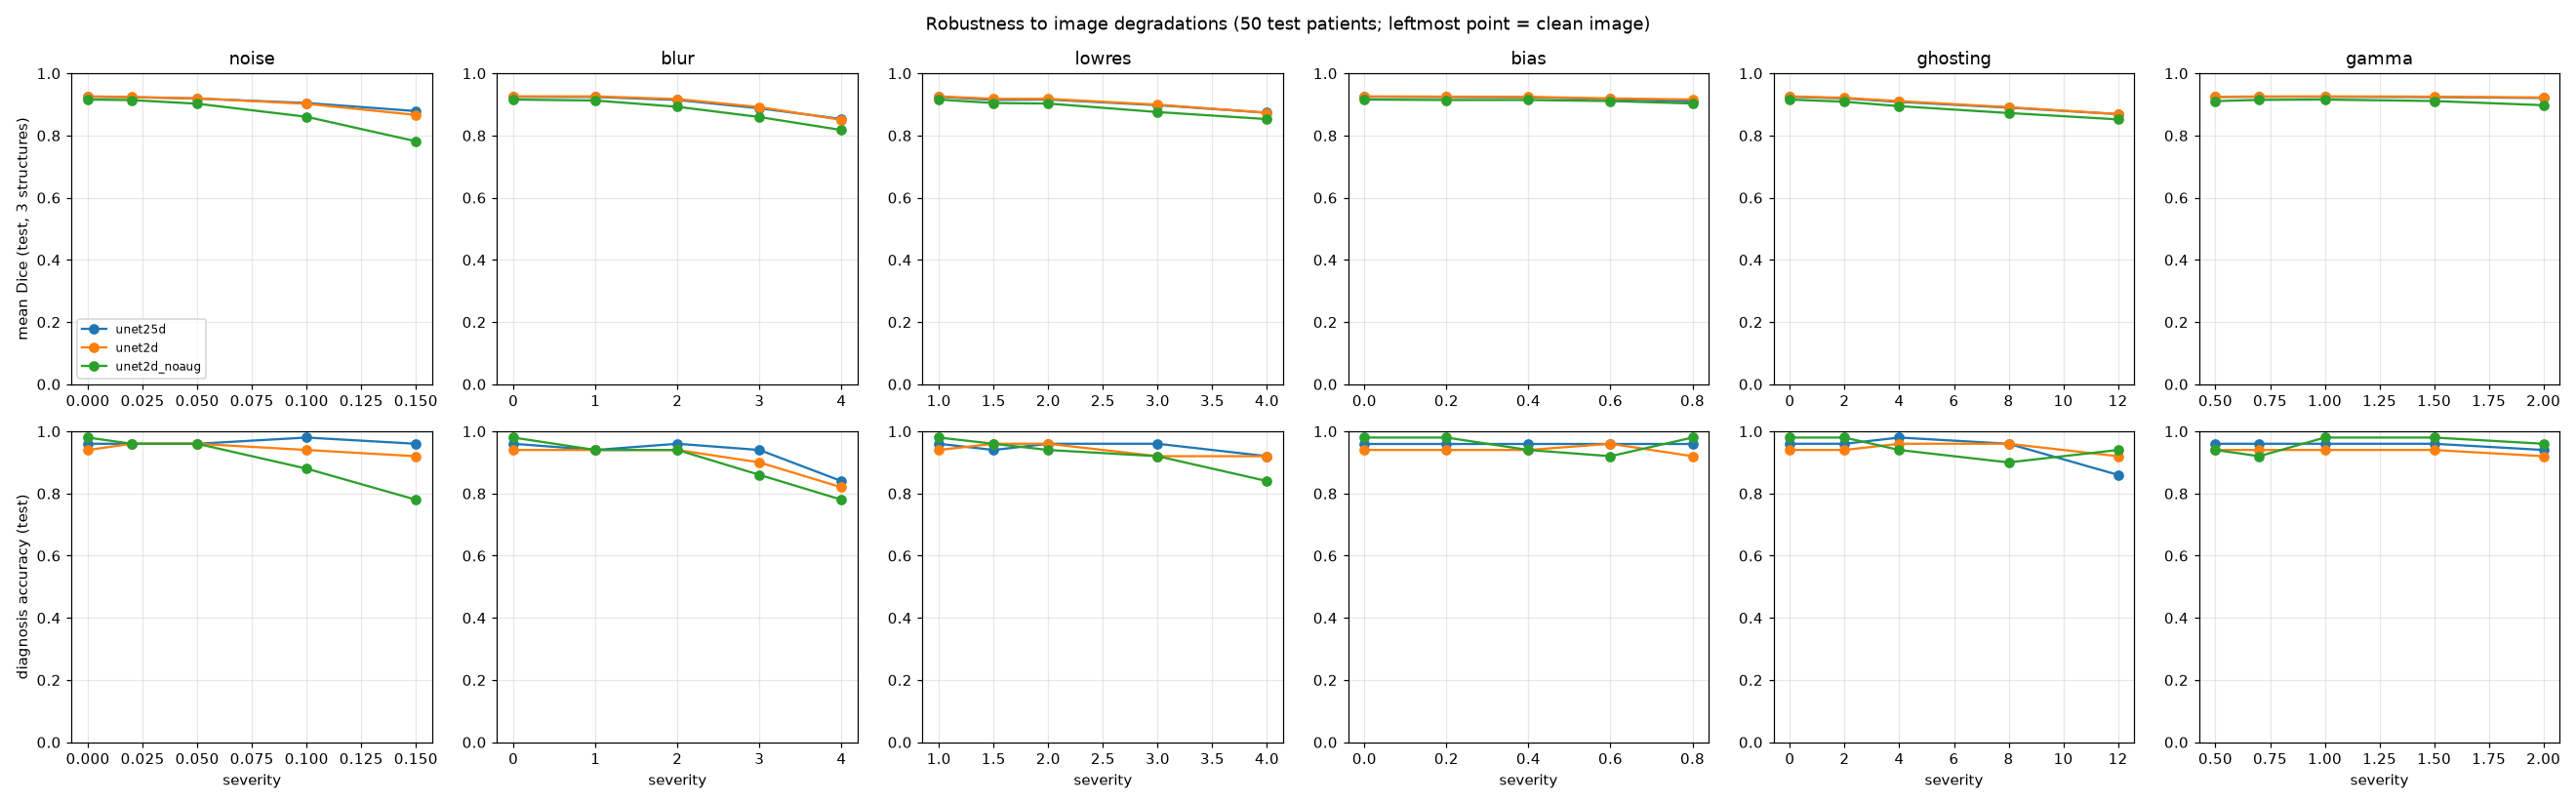

{
 "seed": 0,
 "n": 50,
 "all": {
  "energy_in_heart": 0.23237925678491592,
  "heart_area": 0.08169790638280426,
  "enrichment": 2.8419225495928235,
  "pointing_game": 0.96,
  "energy_on_heart_slices": 0.976527134180069
 },
 "wrong": {
  "n": 8,
  "energy_in_heart": 0.1938401237130165,
  "enrichment": 2.501108207799782,
  "pointing_game": 0.75
 },
 "correct": {
  "n": 42,
  "energy_in_heart": 0.2397200440367063,
  "enrichment": 2.906839567077212,
  "pointing_game": 1.0
 }
}


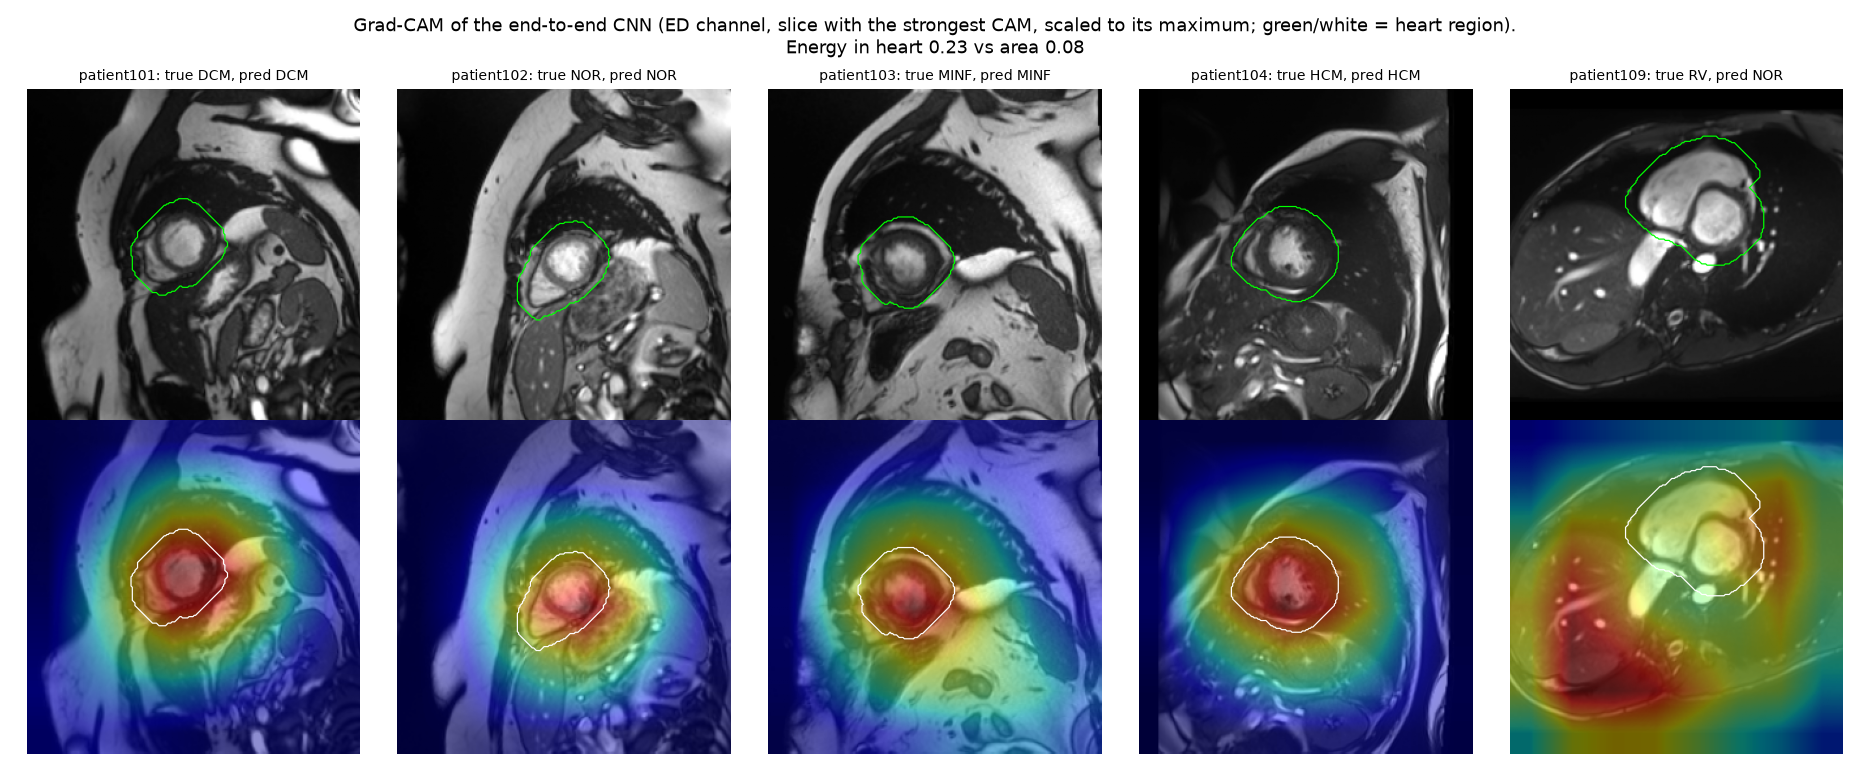

In [20]:
rc = pd.read_csv(R / "robustness" / "robustness_cls.csv")
display(rc.pivot_table(index=["degradation", "level"], columns="cfg", values=["mean_dice", "diag_acc"]))
fig("robustness/fig_degradations.png"); fig("robustness/fig_robustness.png")
print(json.dumps(jload("cls/gradcam_summary.json"), indent=1)); fig("cls/fig_gradcam.png")

## 8. Sensitivity to the split and the evaluation design

How much would the diagnosis conclusions change with another split? (A) the nested CV repeated with 10 re-drawn
fold assignments; (B) all 150 patients pooled and 20 random stratified 100/50 train/test splits. Main classifier
(logistic regression). Limitation: the segmentation models are not retrained per split (that would cost ~6.5
GPU-hours per split); every patient's masks come from models that never saw that patient. The end-to-end CNN's
seed-to-seed spread (5 seeds) is in section 6.

In [21]:
show_code('acdc/split_sensitivity.py')

**`acdc/split_sensitivity.py`**

"""How sensitive are the diagnosis conclusions to the split? (course requirement: "how sensitive the conclusions are to
the train/test split and evaluation design")

Classifier: the main one, multinomial logistic regression with C tuned by inner 5-fold CV (classify.make_model).
Feature sources: gt (expert masks, oracle), unet2d, classical_lgbm (predicted masks), image (no segmentation).

  A) Fold sensitivity: the nested CV on the 100 training patients repeated with 10 new random stratified 5-fold
     assignments (seeds 1-10) instead of the frozen folds.
  B) Train/test split sensitivity: pool all 150 patients and draw 20 random stratified 100/50 splits (seeds 1-20);
     train on 100 (C tuned inside), test on 50. Compared with the official split.

Limitation: the segmentations are NOT re-trained for every split (that would mean re-training 5 U-Nets, ~6.5 GPU-hours
per split). Every patient's predicted masks come from models that never saw that patient (out-of-fold for training
patients, the 5-fold ensemble for test patients), so they are honest, but only the classifier stage is re-split.

Output: results/cls/split_sensitivity.csv (one row per repeat), results/cls/split_sensitivity_summary.csv,
        results/cls/fig_split_sensitivity.png

    python -m acdc.split_sensitivity
"""
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.model_selection import StratifiedKFold, train_test_split  # noqa: E402

from acdc.classify import OUT, make_model, metrics, table  # noqa: E402
from acdc.common import GROUPS  # noqa: E402

SOURCES = {"gt": "expert masks (oracle)", "unet2d": "U-Net masks", "classical_lgbm": "classical masks",
           "image": "image features (no segm.)"}
ENC = {g: i for i, g in enumerate(GROUPS)}


def main():
    rows = []
    for src, label in SOURCES.items():
        tab = table(src)
        feats = [c for c in tab.columns if c not in ("pid", "split", "fold", "group")]
        tr = tab[tab.split == "train"].reset_index(drop=True)
        X, y = tr[feats].values, tr.group.map(ENC).values
        # A) nested CV with re-drawn folds
        for seed in range(1, 11):
            oof = np.zeros((len(tr), len(GROUPS)))
            for fit, val in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
                oof[val] = make_model("logreg", len(feats)).fit(X[fit], y[fit]).predict_proba(X[val])
            m = metrics(oof, y, n_boot=1)
            rows.append({"protocol": "A: CV, re-drawn folds", "source": src, "label": label, "seed": seed,
                         "acc": m["acc"], "macro_f1": m["macro_f1"], "nll": m["nll"]})
        # B) random 100/50 train/test splits of all 150 patients
        Xall, yall = tab[feats].values, tab.group.map(ENC).values
        for seed in range(1, 21):
            i_tr, i_te = train_test_split(np.arange(len(tab)), test_size=50, stratify=yall, random_state=seed)
            p = make_model("logreg", len(feats)).fit(Xall[i_tr], yall[i_tr]).predict_proba(Xall[i_te])
            m = metrics(p, yall[i_te], n_boot=1)
            rows.append({"protocol": "B: random 100/50 split", "source": src, "label": label, "seed": seed,
                         "acc": m["acc"], "macro_f1": m["macro_f1"], "nll": m["nll"]})
        print(src, "done", flush=True)

    df = pd.DataFrame(rows)
    df.to_csv(OUT / "split_sensitivity.csv", index=False)

    # official numbers (frozen folds / official split) from classify.py, for reference
    off = pd.read_csv(OUT / "summary.csv")
    off = off[(off.classifier == "logreg") & (off.train_source == off.test_source)].set_index(["train_source", "eval"])
    s = df.groupby(["protocol", "source", "label"]).agg(acc_mean=("acc", "mean"), acc_sd=("acc", "std"),
                                                         acc_min=("acc", "min"), acc_max=("acc", "max"),
                                                         nll_mean=("nll", "m

In [22]:
if RUN["split_sensitivity"]:
    run("python -m acdc.split_sensitivity")

,protocol,source,label,acc_mean,acc_sd,acc_min,acc_max,nll_mean,n,acc_official,unet2d_minus_this_mean,unet2d_better_in
0,"A: CV, re-drawn folds",classical_lgbm,classical masks,0.596,0.013,0.57,0.61,1.212,10,0.62,0.330,10/10 (ties 0)
1,"A: CV, re-drawn folds",gt,expert masks (oracle),0.955,0.016,0.94,0.99,0.120,10,0.97,-0.029,0/10 (ties 0)
2,"A: CV, re-drawn folds",image,image features (no segm.),0.384,0.032,0.34,0.44,1.652,10,0.43,0.542,10/10 (ties 0)
3,"A: CV, re-drawn folds",unet2d,U-Net masks,0.926,0.008,0.91,0.94,0.222,10,0.92,NaN,NaN
4,B: random 100/50 split,classical_lgbm,classical masks,0.571,0.062,0.42,0.68,1.198,20,0.58,0.362,20/20 (ties 0)
5,B: random 100/50 split,gt,expert masks (oracle),0.950,0.028,0.88,1.00,0.159,20,0.96,-0.017,3/20 (ties 4)
6,B: random 100/50 split,image,image features (no segm.),0.416,0.077,0.24,0.54,1.465,20,0.48,0.517,20/20 (ties 0)
7,B: random 100/50 split,unet2d,U-Net masks,0.933,0.028,0.86,0.98,0.213,20,0.94,NaN,NaN


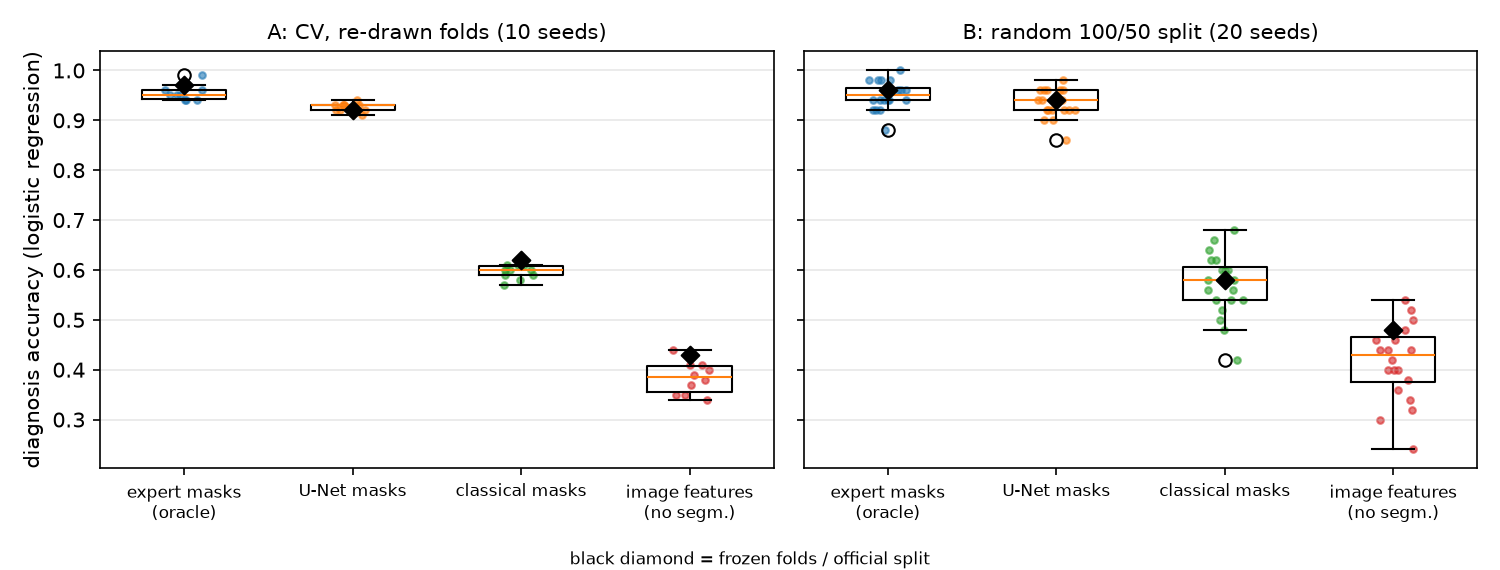

In [23]:
p = R / "cls" / "split_sensitivity_summary.csv"
if p.exists():
    display(pd.read_csv(p)); fig("cls/fig_split_sensitivity.png")

## 9. Complexity: is the extra complexity worth it?

Parameters, FLOPs, training time (GPU-minutes on one L40S), inference time per patient on GPU and on CPU, for every
rung of the ladder, and the measured latency of the deployed demo (2 CPUs).

In [24]:
show_code('acdc/complexity.py')

**`acdc/complexity.py`**

"""Step 10 - complexity / cost of every model (run when the GPU is idle).

    python -m acdc.complexity
Writes results/complexity.csv: parameters, FLOPs (forward pass), training time, and inference time per patient (ED + ES
volumes, median of repeated runs) on the GPU and on the CPU (4 threads), for one model and for the deployed ensemble.
"""
import json
import time

import joblib
import numpy as np
import pandas as pd
import torch
from torch.utils.flop_counter import FlopCounterMode

from acdc.common import RESULTS, WORK
from acdc.infer import load_model, predict_volume
from acdc.seg_baseline import volume_features
from acdc.train_cls import SliceNet, load_stack


def flops(model, x):
    with FlopCounterMode(display=False) as fc:
        with torch.no_grad():
            model(x)
    return fc.get_total_flops()


def timeit(fn, n=5):
    fn()  # warm-up
    ts = []
    for _ in range(n):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t = time.perf_counter()
        fn()
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts))


def main():
    torch.set_num_threads(4)
    pid = "patient101"  # typical test patient (10 slices)
    d = np.load(WORK / "cache" / f"{pid}.npz")
    vols = [torch.from_numpy(d[f"img_{p}"].astype(np.float32)) for p in ("ED", "ES")]
    rows = []
    for cfg in ("unet2d", "unet25d", "unet2d_noaug", "unet2d_ce"):
        if not (WORK / "runs" / f"{cfg}_f4" / "model.pt").exists():
            continue
        mods, cks = zip(*[load_model(WORK / "runs" / f"{cfg}_f{f}" / "model.pt") for f in range(5)])
        in_ch = cks[0]["args"]["in_ch"]
        r = {"model": f"U-Net ({cfg})", "params_M": cks[0]["n_params"] / 1e6,
             "gflops_per_slice_256": flops(mods[0], torch.randn(1, in_ch, 256, 256, device="cuda")) / 1e9,
             "train_gpu_min_per_model": float(np.mean([c["train_minutes"] for c in cks])), "n_models": 5}
        r["infer_gpu_s_1model"] = timeit(lambda: [predict_volume(mods[0], v, in_ch, tta=False) for v in vols])
        r["infer_gpu_s_ensemble_tta"] = timeit(lambda: [predict_volume(list(mods), v, in_ch, tta=True) for v in vols], 3)
        cpu = load_model(WORK / "runs" / f"{cfg}_f0" / "model.pt", "cpu")[0]
        r["infer_cpu_s_1model"] = timeit(lambda: [predict_volume(cpu, v, in_ch, tta=False, device="cpu") for v in vols], 2)
        rows.append(r)
        print(r, flush=True)

    lg = WORK / "runs" / "classical_lgbm.joblib"
    if lg.exists():
        models = joblib.load(lg)
        info = json.loads((RESULTS / "seg" / "classical_lgbm_info.json").read_text())
        m0 = models[0][0]
        feats = [volume_features(v.numpy()) for v in vols]
        r = {"model": "classical pixel classifier (LightGBM)", "params_M": float("nan"),
             "n_trees": int(m0.best_iteration) * 4, "train_gpu_min_per_model": float("nan"),
             "train_cpu_min_all_folds": info["train_minutes"], "n_models": 5}
        r["infer_cpu_s_features"] = timeit(lambda: [volume_features(v.numpy()) for v in vols], 2)
        r["infer_cpu_s_1model"] = r["infer_cpu_s_features"] + timeit(
            lambda: [m0.predict(f.reshape(-1, f.shape[-1]), num_iteration=m0.best_iteration, num_threads=4) for f in feats], 2)
        rows.append(r)
        print(r, flush=True)

    ck0 = WORK / "runs" / "cls_resnet18_s0_f0" / "model.pt"
    if ck0.exists():
        ck = torch.load(ck0, map_location="cpu", weights_only=False)
        m = SliceNet(pretrained=False)
        m.load_state_dict(ck["model"])
        x = load_stack(pid).float()
        mg = m.cuda().eval()
        r = {"model": "end-to-end CNN (ResNet-18 slices)", "params_M": sum(p.numel() for p in m.parameters()) / 1e6,
             "gflops_per_patient": flops(mg, [x.cuda()]) / 1e9, "n_slices": len(x), "n_models": 5,
             "train_gpu_min_per_model": float(np.mean([torch.load(p, map_location="cpu", weights_only=False)["

In [25]:
display(pd.read_csv(R / "complexity.csv").set_index("model"))
print(json.dumps(jload("deploy_test.json"), indent=1))

,params_M,gflops_per_slice_256,train_gpu_min_per_model,n_models,infer_gpu_s_1model,infer_gpu_s_ensemble_tta,infer_cpu_s_1model,n_trees,train_cpu_min_all_folds,infer_cpu_s_features,gflops_per_patient,n_slices,fit_cpu_s_incl_grid_search
model,,,,,,,,,,,,,
U-Net (unet2d),3.347e+01,29.548,78.138,5.0,0.054,0.561,5.908,NaN,NaN,NaN,NaN,NaN,NaN
U-Net (unet25d),3.348e+01,29.624,77.243,5.0,0.039,0.546,5.855,NaN,NaN,NaN,NaN,NaN,NaN
U-Net (unet2d_noaug),3.347e+01,29.548,72.698,5.0,0.035,0.539,5.789,NaN,NaN,NaN,NaN,NaN,NaN
classical pixel classifier (LightGBM),NaN,NaN,NaN,5.0,NaN,NaN,37.994,1380.0,4.529,0.468,NaN,NaN,NaN
end-to-end CNN (ResNet-18 slices),1.118e+01,NaN,0.516,5.0,0.003,NaN,0.157,NaN,NaN,NaN,47.375,10.0,NaN
cardiac features + logistic regression,1.150e-04,NaN,NaN,NaN,NaN,NaN,0.033,NaN,NaN,NaN,NaN,NaN,7.328


{
 "url": "https://acdc-cardiac-aub.fly.dev/",
 "server": "Fly.io performance-2x (2 dedicated CPUs, 4 GB RAM), region fra",
 "patient": "patient101",
 "reference_group": "DCM",
 "first_page_load_seconds": 16.9,
 "calls": [
  {
   "call": "single_first",
   "ensemble": false,
   "seconds": 25.5,
   "pred_two_stage": "DCM (dilated cardiomyopathy)",
   "pred_cnn": "DCM (dilated cardiomyopathy)"
  },
  {
   "call": "single_warm",
   "ensemble": false,
   "seconds": 17.9,
   "pred_two_stage": "DCM (dilated cardiomyopathy)",
   "pred_cnn": "DCM (dilated cardiomyopathy)"
  },
  {
   "call": "ensemble",
   "ensemble": true,
   "seconds": 71.5,
   "pred_two_stage": "DCM (dilated cardiomyopathy)",
   "pred_cnn": "DCM (dilated cardiomyopathy)"
  }
 ],
 "date_utc": "2026-11-20 16:13",
 "note": "wall-clock from an AWS client incl. upload; first_page_load includes machine start if it was stopped; single_first includes lazy model loading"
}


## 10. Final models, demo and deployment

`acdc/export_models.py` packages the final models (5 U-Nets, 5 CNNs, the feature classifier, config) into
`deploy/models` (also published as `acdc_models.tar.gz` in the GitHub release). `acdc/app.py` is the Gradio demo
(upload ED/ES frames or pick an ACDC test patient: contours, clinical indices, both diagnoses, Grad-CAM, uncertainty
warning). `deploy/` holds the CPU Docker image and the Fly.io configuration; `acdc/test_deploy.py` times the live demo.

In [26]:
show_code('acdc/export_models.py', 'acdc/infer.py', 'acdc/app.py', 'acdc/test_deploy.py', 'deploy/Dockerfile', 'deploy/fly.toml', 'deploy/requirements.txt', 'acdc/finalize.sh')

**`acdc/export_models.py`**

"""Collect the final models for the demo / deployment into one folder (default deploy/models).

    python -m acdc.export_models --seg_cfg unet2d --out deploy/models

  unet_f{0..4}.pt          segmentation U-Nets (5 folds), weights stored in float16 to halve the size
  cnn_f{0..4}.pt           end-to-end ResNet-18 diagnosis CNNs (seed 0, 5 folds), float16
  feature_clf.joblib       logistic regression on cardiac features, trained on all 100 training patients with the
                           OUT-OF-FOLD predicted features of the same U-Net (the automatic pipeline, as evaluated)
  config.json              in_ch, feature names, uncertainty threshold (90th percentile of the out-of-fold entropy
                           score on the training patients), CNN temperature
  examples/                a few ACDC test patients (ED/ES frames + Info.cfg) for the demo, CC BY-NC-SA 4.0, with citation
"""
import argparse
import json
import shutil
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch

from acdc.classify import make_model
from acdc.common import GROUPS, RESULTS, WORK, patient_dir, read_info
from acdc.features import feature_table



def half(sd):
    return {k: (v.half() if v.is_floating_point() else v) for k, v in sd.items()}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--seg_cfg", default="unet2d")
    ap.add_argument("--cnn_tag", default="resnet18")
    ap.add_argument("--cnn_seed", type=int, default=0)
    ap.add_argument("--out", default="deploy/models")
    args = ap.parse_args()
    out = Path(args.out)
    (out / "examples").mkdir(parents=True, exist_ok=True)
    for f in range(5):
        ck = torch.load(WORK / "runs" / f"{args.seg_cfg}_f{f}" / "model.pt", map_location="cpu", weights_only=False)
        torch.save({"model": half(ck["model"]), "args": ck["args"]}, out / f"unet_f{f}.pt")
        ck = torch.load(WORK / "runs" / f"cls_{args.cnn_tag}_s{args.cnn_seed}_f{f}" / "model.pt", map_location="cpu", weights_only=False)
        torch.save({"model": half(ck["model"])}, out / f"cnn_f{f}.pt")
    in_ch = torch.load(out / "unet_f0.pt", weights_only=False)["args"]["in_ch"]

    ft = feature_table(args.seg_cfg)
    feats = [c for c in ft.columns if c not in ("pid", "split", "fold", "group")]
    tr = ft[ft.split == "train"]
    enc = {g: i for i, g in enumerate(GROUPS)}
    clf = make_model("logreg", len(feats)).fit(tr[feats].values, tr.group.map(enc).values)
    joblib.dump(clf.best_estimator_, out / "feature_clf.joblib")

    # the app predicts without test-time augmentation -> threshold from the no-TTA out-of-fold predictions if available
    m = RESULTS / "seg" / f"{args.seg_cfg}_notta_metrics.csv"
    seg = pd.read_csv(m if m.exists() else RESULTS / "seg" / f"{args.seg_cfg}_metrics.csv")
    thr = float(seg[seg.split == "train"].ent_fg.quantile(0.9))
    temp = None
    seeds = RESULTS / "cls" / "cnn_seeds.csv"
    if seeds.exists():
        s = pd.read_csv(seeds)
        temp = float(s.loc[s.seed == args.cnn_seed, "T"].iloc[0]) if (s.seed == args.cnn_seed).any() else None
    cfg = {"seg_cfg": args.seg_cfg, "in_ch": int(in_ch), "features": feats, "groups": GROUPS,
           "uncertainty_threshold_ent_fg": thr, "cnn_temperature": temp}
    (out / "config.json").write_text(json.dumps(cfg, indent=2))

    meta = pd.read_csv(RESULTS / "acdc_meta.csv")
    examples = meta[meta.split == "test"].groupby("group").pid.first().loc[GROUPS].tolist()  # one test patient per group
    for pid in examples:
        info = read_info(pid)
        dst = out / "examples" / pid
        dst.mkdir(exist_ok=True)
        for ph in ("ED", "ES"):
            shutil.copy(patient_dir(pid) / f"{pid}_frame{info[ph]:02d}.nii.gz", dst / f"{pid}_{ph}.nii.gz")
        shutil.copy(patient_dir(pid) / "Info.cfg", dst / "Info.cfg")
    (out / "examples" / "CITATION.md").write_text(
        "Example images from the ACDC dataset (test patients), CC BY-NC-SA 4.0, non-commercial research use o

**`acdc/infer.py`**

"""Whole-slice inference for the 2D U-Net (used for validation during training, prediction, robustness and the demo)."""
import torch
import torch.nn.functional as F

from acdc.augment import neighbour_stack
from acdc.unet import UNet2D


@torch.no_grad()
def predict_volume(models, img, in_ch=1, tta=True, device="cuda", batch=16):
    """img: (Z,H,W) float tensor at 1.25 mm, normalised. Returns softmax probabilities (Z,4,H,W) on CPU, averaged over
    the given models and (if tta) over the 4 mirrorings of the slice. Slices are padded to a multiple of 64 (6 poolings)."""
    if not isinstance(models, (list, tuple)):
        models = [models]
    x = neighbour_stack(img.float(), in_ch)  # (Z,C,H,W)
    Z, C, H, W = x.shape
    ph, pw = (-H) % 64, (-W) % 64
    x = F.pad(x, (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2), value=float(img.min()))
    flips = [(), (2,), (3,), (2, 3)] if tta else [()]
    out = torch.zeros(Z, 4, H + ph, W + pw)
    for i in range(0, Z, batch):
        xb = x[i:i + batch].to(device)
        acc = 0
        for m in models:
            for f in flips:
                inp = xb.flip(f) if f else xb
                with torch.autocast("cuda", dtype=torch.bfloat16, enabled=(device == "cuda")):
                    logits = m(inp)
                p = torch.softmax(logits.float(), 1)
                acc = acc + (p.flip(f) if f else p)
        out[i:i + batch] = (acc / (len(models) * len(flips))).cpu()
    return out[:, :, ph // 2: ph // 2 + H, pw // 2: pw // 2 + W]


def load_model(path, device="cuda"):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = UNet2D(in_ch=ck["args"]["in_ch"])
    m.load_state_dict(ck["model"])
    m.deep_supervision = False
    return m.to(device).eval(), ck

**`acdc/app.py`**

"""Gradio demo: cardiac cine-MRI segmentation, clinical indices and diagnosis (course project, NOT for clinical use).

    python -m acdc.app --models_dir deploy/models            # local, CPU or GPU
    python -m acdc.app --models_dir deploy/models --public   # deployment mode (binds 0.0.0.0:7860, CPU)

Input: the end-diastolic (ED) and end-systolic (ES) short-axis frames as NIfTI files (as in ACDC), patient height and
weight - or one of the bundled ACDC test patients. Output: segmentation overlays for every slice, LV/RV volumes, ejection
fractions and myocardial mass, the diagnosis of the two-stage pipeline (U-Net -> cardiac features -> logistic
regression) and of the end-to-end CNN (with Grad-CAM), and an uncertainty warning when the segmentation is unreliable.
"""
import argparse
import json
import tempfile
from pathlib import Path

import gradio as gr
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch

from acdc.augment import to_canvas
from acdc.common import keep_largest_component, normalize, probs_to_original, resample_image
from acdc.features import patient_features
from acdc.gradcam import gradcam
from acdc.infer import predict_volume
from acdc.predict_seg import entropy, uncertainty_summary
from acdc.train_cls import CROP, SliceNet
from acdc.unet import UNet2D

BANNER = ("**Course project demo (AUB Machine Learning, Fall 2026) — not a medical device, not for clinical use.** "
          "Models trained on the ACDC dataset (Bernard et al., IEEE TMI 2018; CC BY-NC-SA 4.0).")
COLORS = np.array([[0, 0, 0, 0], [0.2, 0.5, 1, 0.5], [0.1, 0.85, 0.3, 0.5], [1, 0.3, 0.2, 0.5]])


class Models:
    def __init__(self, d: Path, device):
        self.d, self.device = d, device
        self.cfg = json.loads((d / "config.json").read_text())
        self._unet, self._cnn, self._clf = None, None, None

    def unets(self):
        if self._unet is None:
            self._unet = []
            for f in range(5):
                ck = torch.load(self.d / f"unet_f{f}.pt", map_location="cpu", weights_only=False)
                m = UNet2D(in_ch=ck["args"]["in_ch"])
                m.load_state_dict({k: v.float() for k, v in ck["model"].items()})
                m.deep_supervision = False
                self._unet.append(m.to(self.device).eval())
        return self._unet

    def cnns(self):
        if self._cnn is None:
            self._cnn = []
            for f in range(5):
                m = SliceNet(pretrained=False)
                m.load_state_dict({k: v.float() for k, v in torch.load(self.d / f"cnn_f{f}.pt", map_location="cpu")["model"].items()})
                self._cnn.append(m.to(self.device).eval())
        return self._cnn

    def clf(self):
        if self._clf is None:
            self._clf = joblib.load(self.d / "feature_clf.joblib")
        return self._clf


def load_nifti(f):
    im = nib.load(f)
    a = np.asarray(im.dataobj, dtype=np.float32)
    if a.ndim == 4:
        raise gr.Error("Please upload single 3D frames (ED and ES), not the 4D cine file.")
    return a.transpose(2, 0, 1), tuple(float(s) for s in im.header.get_zooms()[:3]), im.affine


def overlay(img, seg, title):
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(img.T, cmap="gray")
    ax.imshow(COLORS[seg.T], interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
    fig.tight_layout(pad=0.2)
    fig.canvas.draw()
    arr = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return arr


def make_app(M: Models, examples_dir: Path):
    groups = M.cfg["groups"]
    names = {"NOR": "normal", "MINF": "previous myocardial infarction", "DCM": "dilated cardiomyopathy",
             "HCM": "hypertrophic cardiomyopathy", "RV": "abnormal right ventricle"}
    ex = sorted(p.name for p in examples_dir.iterdir() if p.is_dir()) if examples_dir.exists() else []

    def run(ed_file, es_file, height, w

... (6 outputs left out)

**`deploy/requirements.txt`**

# CPU-only runtime for the public demo (versions match the training environment, uv.lock).
--extra-index-url https://download.pytorch.org/whl/cpu
torch==2.11.0+cpu
torchvision==0.26.0+cpu
numpy==2.5.4
scipy==1.18.1
pandas==3.1.1
matplotlib==3.11.2
nibabel==5.5.0
scikit-learn==1.9.1   # must match the version that pickled feature_clf.joblib
joblib==1.6.0
gradio==6.31.0

**`acdc/finalize.sh`**

#!/usr/bin/env bash
# Re-run every evaluation on whatever predictions exist, rebuild results/summary.md, commit and push the results.
# Safe to run several times (each step overwrites its own outputs). Used as the last steps of the GPU queue.
set -u
cd "$(dirname "$0")/.."
UV=${UV:-$(command -v uv || echo ~/.local/bin/uv)}  # uv on PATH, else the default install location
SEG=""; for c in classical_lgbm unet2d unet25d unet2d_noaug unet2d_ce unet2d_notta unet2d_nopp; do
  [ -f results/seg/${c}_metrics.csv ] && SEG="$SEG $c"; done
SRC=""; for c in unet25d unet2d_noaug unet2d_ce; do [ -f results/seg/${c}_metrics.csv ] && SRC="$SRC $c"; done
echo "segmentation configs:$SEG | extra diagnosis sources:$SRC"
$UV run python -m acdc.evaluate_seg --cfgs $SEG
[ -n "$SRC" ] && $UV run python -m acdc.classify --sources $SRC
$UV run python -m acdc.evaluate_cls --seg_cfgs unet2d unet25d classical_lgbm $SRC
$UV run python -m acdc.summarize
git add results README.md acdc
git commit -q -m "Results update: evaluations re-run on all available models (${SEG# })" && git push -q origin main
echo "finalize done"

In [27]:
if RUN["evaluate"]:
    run("python -m acdc.evaluate_seg --cfgs classical_lgbm unet2d unet25d unet2d_noaug unet2d_ce unet2d_notta unet2d_nopp")
    run("python -m acdc.evaluate_cls --seg_cfgs unet2d unet25d classical_lgbm unet2d_noaug unet2d_ce")
    run("python -m acdc.robustness --cfgs unet2d unet2d_noaug unet25d && python -m acdc.gradcam && python -m acdc.complexity && python -m acdc.summarize")

## 11. Headline results (read from `results/`)
`results/summary.md` (made by `acdc/summarize.py`) has every table; the cell below collects the main numbers.

In [28]:
show_code('acdc/summarize.py')

**`acdc/summarize.py`**

"""Step 11 - collect all results into results/summary.md (every number is read from a file in results/).

    python -m acdc.summarize
"""
import json

import pandas as pd

from acdc.common import RESULTS

SEG_NAMES = {"classical_lgbm": "Classical (LightGBM pixel classifier)", "unet2d": "U-Net 2D (main)",
             "unet25d": "U-Net 2.5D (3 slices)", "unet2d_noaug": "U-Net 2D, no augmentation",
             "unet2d_ce": "U-Net 2D, CE loss only", "unet2d_notta": "U-Net 2D, no TTA", "unet2d_nopp": "U-Net 2D, no post-processing"}


def f(x, d=3):
    return "–" if pd.isna(x) else f"{x:.{d}f}"


def md(df):
    return df.to_markdown(index=False)


def seg_section():
    out = ["## 1. Segmentation\n"]
    s = pd.read_csv(RESULTS / "seg" / "seg_summary.csv")
    for ev, title in (("test", "Test set (50 patients, 5-fold ensemble)"), ("cv", "Cross-validation (100 training patients, out-of-fold)")):
        rows = []
        for cfg in [c for c in SEG_NAMES if c in s.cfg.unique()]:
            r = {"model": SEG_NAMES[cfg]}
            for ph in ("ED", "ES"):
                for st in ("LV", "RV", "MYO"):
                    d = s[(s.cfg == cfg) & (s["eval"] == ev) & (s.phase == ph) & (s.structure == st)].iloc[0]
                    r[f"{st} {ph}"] = f"{f(d.dice)} / {f(d.hd95, 1)}"
            d = s[(s.cfg == cfg) & (s["eval"] == ev)]
            r["mean Dice"] = f(d.dice.mean())
            rows.append(r)
        out += [f"### {title}: Dice / HD95 (mm)\n", md(pd.DataFrame(rows)), ""]
    p = RESULTS / "seg" / "seg_paired_tests.csv"
    if p.exists():
        t = pd.read_csv(p)
        t = t.assign(**{c: t[c].map(f) for c in ("ref_mean", "other_mean", "diff")}, wilcoxon_p=t.wilcoxon_p.map(lambda x: f"{x:.2g}"))
        out += ["### Paired Wilcoxon tests (per-patient mean over structures and phases)\n", md(t), ""]
    c = pd.read_csv(RESULTS / "seg" / "clinical_agreement.csv")
    c = c[c.cfg.isin(["unet2d", "classical_lgbm", "unet25d"])]
    c = c.assign(**{k: c[k].map(lambda x: f(x, 2)) for k in ("pearson_r", "bias", "loa_lo", "loa_hi", "mae")})
    out += ["### Clinical indices vs expert segmentation (Pearson r, bias, 95% limits of agreement, MAE)\n", md(c), ""]
    sp = pd.read_csv(RESULTS / "seg" / "slice_position.csv")
    sp = sp[sp.cfg == "unet2d"].pivot_table(index=["eval", "structure"], columns="position", values="mean").reset_index()
    out += ["### U-Net 2D: slice-wise Dice by position (base / mid / apex thirds)\n", md(sp.round(3)), ""]
    g = pd.read_csv(RESULTS / "seg" / "dice_by_group.csv")
    out += ["### Dice by diagnostic group\n", md(g.round(3)), ""]
    u = RESULTS / "seg" / "uncertainty.csv"
    if u.exists():
        out += ["### Uncertainty as a failure detector (failure = any structure Dice < 0.80)\n", md(pd.read_csv(u).round(3)), ""]
    out += ["Figures: `seg/fig_dice_box.png`, `seg/fig_bland_altman.png`, `seg/fig_examples_best_worst.png`, `fig_examples.png`\n"]
    return out


def cls_section():
    out = ["## 2. Diagnosis (5 classes)\n"]
    p = pd.read_csv(RESULTS / "cls" / "pipelines.csv")
    cols = ["pipeline", "eval", "acc", "acc_lo", "acc_hi", "macro_f1", "nll", "brier", "ece"]
    p = p[[c for c in cols + ["acc_sd", "nll_sd"] if c in p.columns]].copy()
    for c in p.columns[2:]:
        p[c] = p[c].map(f)
    for ev in ("test", "cv"):
        out += [f"### {'Test (50 patients)' if ev == 'test' else 'Nested CV, out-of-fold (100 training patients)'}\n",
                md(p[p["eval"] == ev]), ""]
    for name, title in (("mcnemar.csv", "McNemar tests vs the main automatic pipeline"), ("cnn_seeds.csv", "End-to-end CNN per seed (with temperature scaling fitted on out-of-fold predictions)")):
        q = RESULTS / "cls" / name
        if q.exists():
            out += [f"### {title}\n", md(pd.read_csv(q).round(3)), ""]
    g = RESULTS / "cls" / "gradcam_summary.json"
    if g.exists():
        out += ["### Grad-CAM of the end-to-end CNN vs expert heart contours (test)\n", "```json", g.read_text(), "`

In [29]:
s = pd.read_csv(R / "seg" / "seg_summary.csv").query("eval == 'test'").groupby("cfg").dice.mean()
pl = pd.read_csv(R / "cls" / "pipelines.csv").set_index(["pipeline", "eval"])
rows = [
    ("Segmentation, test mean Dice: classical LightGBM", s["classical_lgbm"]),
    ("Segmentation, test mean Dice: U-Net 2D", s["unet2d"]),
    ("Diagnosis accuracy, test: image features (no segmentation), logreg", pl.loc[("image->image logreg", "test"), "acc"]),
    ("Diagnosis accuracy, test: classical masks -> features -> logreg", pl.loc[("classical_lgbm->classical_lgbm logreg", "test"), "acc"]),
    ("Diagnosis accuracy, test: U-Net masks -> features -> logreg", pl.loc[("unet2d->unet2d logreg", "test"), "acc"]),
    ("Diagnosis accuracy, test: expert masks (oracle) -> logreg", pl.loc[("gt->gt logreg", "test"), "acc"]),
    ("Diagnosis accuracy, test: end-to-end CNN ensemble", pl.loc[("cnn_ensemble", "test"), "acc"]),
    ("Diagnosis accuracy, CV: U-Net pipeline", pl.loc[("unet2d->unet2d logreg", "cv"), "acc"]),
    ("Diagnosis accuracy, CV: end-to-end CNN ensemble", pl.loc[("cnn_ensemble", "cv"), "acc"]),
]
display(pd.DataFrame(rows, columns=["result", "value"]).set_index("result"))

,value
result,
"Segmentation, test mean Dice: classical LightGBM",0.639
"Segmentation, test mean Dice: U-Net 2D",0.928
"Diagnosis accuracy, test: image features (no segmentation), logreg",0.480
"Diagnosis accuracy, test: classical masks -> features -> logreg",0.580
"Diagnosis accuracy, test: U-Net masks -> features -> logreg",0.940
"Diagnosis accuracy, test: expert masks (oracle) -> logreg",0.960
"Diagnosis accuracy, test: end-to-end CNN ensemble",0.860
"Diagnosis accuracy, CV: U-Net pipeline",0.920
"Diagnosis accuracy, CV: end-to-end CNN ensemble",0.750
